In [2]:
'''
gonna check out all the prediction images


'''

'\ncopied from full_image_extractions but for the larger set of implanted images \nwith the new CNN\n\ni make figures here but they are coppied and improved in plots_figures\n\n\nold nb goal: the goal of this notebook is to run cnn and get efficiencies\nand such from the folder of full_image_implants that i \njust made.\n\n'

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import imageio as iio
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from astropy.io import fits
import scipy.ndimage as snm

2024-10-07 12:48:18.680500: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [8]:

from tqdm.auto import tqdm
import os
from pylab import cm
import matplotlib as mpl
import get_postage_stamps as gpsf
import pandas as pd

In [19]:
import plot_time_series as pts
import precision_recall as pr
import importlib
#importlib.reload(plot_time_series)
import gc #garbage collector
import glob #i don't know if there is a better way to do this but this was the 
#internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff

In [10]:
#some matplotlib defaults
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [11]:
# image_filename_full = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/20210622_minus_extras/ztf_20210622237812_000677_zr_c12_o_0054.fits.fz"
# hdul=fits.open(image_filename_full)
# file1_array = hdul[1].data
# norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array))
# plt.imshow(norm)

In [12]:
#some stuff that will stay the same
wid = 10
# fpath_image = "/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/images/"
# fpath_info = "/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/info/"
# fpath_extractions = "/lustre/lrspec/ZTF_data/2022_1014_copy/full_transient_extractions/"

# image_directory = os.fsencode(fpath_image)



In [7]:
np.empty((5,1)).T

array([[0., 0., 0., 0., 0.]])

In [6]:
# model_best=keras.models.load_model("/home/3155/CNN_jan2")

2024-02-28 12:45:48.724178: I tensorflow/core/common_runtime/process_util.cc:146] Creating new thread pool with default inter op setting: 2. Tune using inter_op_parallelism_threads for best performance.


In [13]:
direcs = ['/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/',
          '/lustre/lrspec/ZTF_data/science_extractions/to_extract/1026_minus_extras/',
          '/lustre/lrspec/ZTF_data/science_extractions/to_extract/20220808_minus_extras/',
         '/lustre/lrspec/ZTF_data/science_extractions/to_extract/20210622_minus_extras/',
'/lustre/lrspec/ZTF_data/science_extractions/to_extract/0820_minus_extras/', 
         '/lustre/lrspec/ZTF_data/science_extractions/to_extract/1014_minus_extras/',
         '/lustre/lrspec/ZTF_data/science_extractions/to_extract/1017_minus_extras/']
          
direcnames = [ '1020', '1026,', '20220808', '20210622', '0820_real_this_time', '1014', '1017']


In [7]:
predsarray = np.load('/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020297847_000449_zr_c16_x_0022._extraction_predsarray_4_predsarray.npy')

In [10]:
predsarray.shape

(9339120, 5)

In [12]:
testimp = np.load("/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/images/ztf_20221014279051_000501_zr_c16_x_0025._implanted10.npy")

In [16]:
nrow, ncol = testimp.shape 
wid=10

In [14]:
nrow, ncol

(3080, 3072)

In [17]:
pimg_pos = predsarray[:,1].reshape(ncol-2*wid, nrow-2*wid) 
pimg_bg = predsarray[:,0].reshape(ncol-2*wid, nrow-2*wid) 
pimg_streak = predsarray[:,4].reshape(ncol-2*wid, nrow-2*wid) 
pimg_neg = predsarray[:,2].reshape(ncol-2*wid, nrow-2*wid) 
pimg_cr = predsarray[:,3].reshape(ncol-2*wid, nrow-2*wid) 

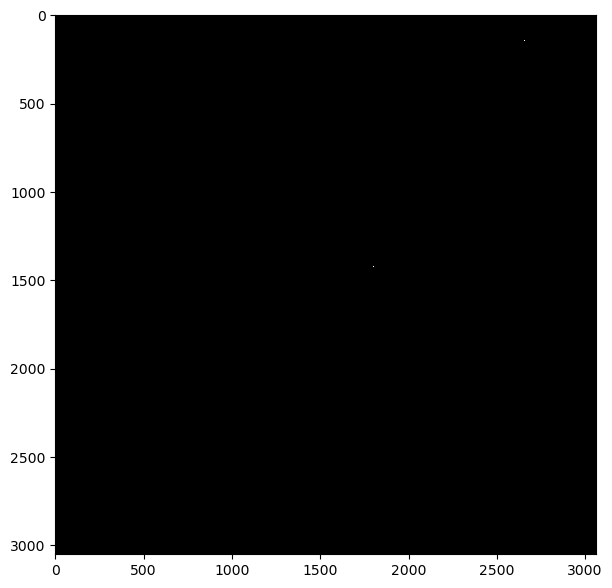

In [19]:
plt.imshow(pimg_pos>.9999)

In [21]:
np.sum(pimg_pos>.9999)

258

In [31]:
def make_obj_list(image, predsarray, abst_thr, fname):
    nrow, ncol = image.shape  
    pimg_pos = predsarray[:,1].reshape(ncol-2*wid, nrow-2*wid) 
    pimg_bg = predsarray[:,0].reshape(ncol-2*wid, nrow-2*wid) 
    pimg_streak = predsarray[:,4].reshape(ncol-2*wid, nrow-2*wid) 
    pimg_neg = predsarray[:,2].reshape(ncol-2*wid, nrow-2*wid) 
    pimg_cr = predsarray[:,3].reshape(ncol-2*wid, nrow-2*wid) 
    
    pimg_both = pimg_pos+pimg_neg
    
    structure = [[1,1,1], [1,1,1], [1,1,1]] #for what counts as one object
    
    #FOR POS
    thrdet = pimg_pos > abst_thr
    threshed = thrdet.T #it takes the transposed pimg
    
    labs, nlabs = snm.label(threshed, structure)
    loc_list_pos = snm.center_of_mass(threshed,labs,range(1,nlabs+1))
    loc_list_pos = np.array(loc_list_pos)
    objsizes_pos = pr.get_objsizes(labs, nlabs)
    

    
    # brightnesses = np.zeros(len(loc_list))
    # # bg_thresh=.1
    # cosmicray = []
    # rows = np.zeros(len(loc_list))
    # cols = np.zeros(len(loc_list))
    # for k, loc in enumerate(loc_list):
    #     (row, col) = loc
    #     rows[k] = int(row)
    #     cols[k] = int(col)
    #     # print("loc = row,col= "+str(loc))
    #     # print(row)
    #     # print(col)
    #     colavg = np.average(pimg_bg.T[:,int(col)]) #not actually the column average
    #     #print("colavg: "+str(colavg) )               
    #     # if colavg>bg_thresh: #column is mostly not background - can adjust this cutoff
    #     cosmicray.append(colavg)
    #     brightnesses[k] = image[int(row)+wid, int(col)+wid]
        
    fnames = np.full(len(loc_list_pos),fname)
    poses = np.full(len(loc_list_pos),"pos")
    if len(loc_list_pos)>0:
        poslist = (np.vstack((fnames, poses, loc_list_pos[:,0], loc_list_pos[:,1], objsizes_pos))).T
    
    #FOR NEG
    thrdet = pimg_neg > abst_thr
    threshed = thrdet.T #it takes the transposed pimg
    
    labs, nlabs = snm.label(threshed, structure)
    loc_list_neg = snm.center_of_mass(threshed,labs,range(1,nlabs+1))
    loc_list_neg = np.array(loc_list_neg)
    
    objsizes_neg = pr.get_objsizes(labs, nlabs)   
    
    fnames = np.full(len(loc_list_neg),fname)
    negs = np.full(len(loc_list_neg),"neg")
        
    if len(loc_list_neg)>0:
        neglist = (np.vstack((fnames, negs, loc_list_neg[:,0], loc_list_neg[:,1], objsizes_neg))).T

    #FOR CRS
    thrdet = pimg_cr > abst_thr
    threshed = thrdet.T #it takes the transposed pimg
    

    labs, nlabs = snm.label(threshed, structure)
    loc_list_cr = snm.center_of_mass(threshed,labs,range(1,nlabs+1))
    loc_list_cr = np.array(loc_list_cr)
    
    objsizes_cr = pr.get_objsizes(labs, nlabs)   
    
    fnames = np.full(len(loc_list_cr),fname)
    if len(loc_list_cr)>0:
        crs = np.full(len(loc_list_cr),"cr")
    # print(np.shape(fnames))
    # print(np.shape(crs))
    # print(np.shape(loc_list_cr[:,0]))
    # print(np.shape(loc_list_cr[:,1]))
    # print(np.shape(objsizes_cr))
        crlist = (np.vstack((fnames, crs, loc_list_cr[:,0], loc_list_cr[:,1], objsizes_cr))).T
    else:
        crlist=0
    #FOR BOTH
    thrdet = pimg_both > abst_thr
    threshed = thrdet.T #it takes the transposed pimg
    

    labs, nlabs = snm.label(threshed, structure)
    loc_list_both = snm.center_of_mass(threshed,labs,range(1,nlabs+1))
    loc_list_both = np.array(loc_list_both)
    
    objsizes_both = pr.get_objsizes(labs, nlabs)   
    
    fnames = np.full(len(loc_list_both),fname)
    boths = np.full(len(loc_list_both),"both")
    if len(loc_list_both)>0:
        bothlist = (np.vstack((fnames, boths, loc_list_both[:,0], loc_list_both[:,1], objsizes_both))).T
    

    del pimg_cr
    del pimg_pos
    del pimg_neg
    del pimg_bg
    del pimg_streak
    del thrdet
    del loc_list_pos
    del loc_list_neg
    del objsizes_pos
    del objsizes_neg
    del labs
    del threshed
    gc.collect()
    

    # np.save(path, n_loc_size_ray_b)
    if crlist!=0:
        listlist = np.vstack((poslist, neglist, crlist, bothlist))
    else:
        listlist = np.vstack((poslist, neglist, bothlist))
    alllist = pd.DataFrame(listlist)
    
    alllist.rename(columns={0: 'filename', 
                                         1: 'type',
                                         2: 'row_from_nn',
                                         3: 'col_from_nn',
                                         4: 'detection_size'}, inplace=True)

    alllist[["row_from_nn", "col_from_nn", 'detection_size']] = alllist[["row_from_nn", "col_from_nn", 'detection_size']].apply(pd.to_numeric)
    # np.save(path, n_loc_size_ray_b)
    return poslist, neglist, crlist, bothlist, alllist

In [ ]:
#, 
# , 1019

# In[87]:


for j in range(len(direcnames)):
    direc = direcs[j]
    direcname = direcnames[j]
    wid = 10
    abst_thr = .9999
    fpath_extractions = "/lustre/lrspec/ZTF_data/science_extractions/"+direcname+"/"
    
    
    for i, file in enumerate(os.listdir(direc)):
        image_filename = os.fsdecode(file)
        filename_start = image_filename[:40]
        image_filename_full = direc+image_filename
            
        print(image_filename_full)
        for iteration in range(1,5):
            hdul=fits.open(image_filename_full)
            file1_array = hdul[iteration].data
            norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array))
            image = norm
            nrow, ncol = image.shape
            path = fpath_extractions+str(filename_start)+"_extraction_predsarray_"+str(iteration)+"_predsarray.npy"
            
            
            predsarray = np.load(path)
            
            poslist, neglist, crlist, bothlist, alllist = make_obj_list(image, predsarray, abst_thr, filename_start)
            
            del norm
            del file1_array
            del image
            del hdul
            
            dpath = fpath_extractions+image_filename+str(iteration)+'alllist'
            
            alllist.to_csv(dpath)
            del poslist
            del neglist
            del crlist
            del bothlist
            del alllist
            gc.collect()
            
#         n_loc_size_ray_b = make_found_transient_list(image, model, abst_thr, wid,  path, filename_start)
        
#         if i==0:
#             df_detections = pd.DataFrame(n_loc_size_ray_b)
#         else:
#             for k in range(len(n_loc_size_ray_b)):
#                 df_detections.loc[len(df_detections)] = n_loc_size_ray_b[k]
#     df_detections.rename(columns={0: 'filename', 
#                                          1: 'row_from_nn',
#                                          2: 'col_from_nn',
#                                          3: 'detection_size',
#                                          4: 'cosmic_ray_flag',
#                                          5: 'max brightness'}, inplace=True)
#     df_detections.to_csv(fpath_extractions+"df_detections_"+str(direcname))
    

In [15]:
alllist = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020154120_000640_zi_c04_x_0005.fits.fz3alllist')

In [17]:
alllist

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size
0,0,ztf_20221020154120_000640_zi_c04_x_0005.,pos,10.500000,2377.00,2
1,1,ztf_20221020154120_000640_zi_c04_x_0005.,pos,16.500000,2391.00,4
2,2,ztf_20221020154120_000640_zi_c04_x_0005.,pos,36.000000,2377.00,1
3,3,ztf_20221020154120_000640_zi_c04_x_0005.,pos,42.714286,34.50,14
4,4,ztf_20221020154120_000640_zi_c04_x_0005.,pos,72.500000,40.00,2
...,...,...,...,...,...,...
1312,1312,ztf_20221020154120_000640_zi_c04_x_0005.,both,3048.000000,2390.00,7
1313,1313,ztf_20221020154120_000640_zi_c04_x_0005.,both,3047.000000,34.00,1
1314,1314,ztf_20221020154120_000640_zi_c04_x_0005.,both,3058.250000,34.25,4
1315,1315,ztf_20221020154120_000640_zi_c04_x_0005.,both,3058.500000,32.00,2


In [18]:
alllist[alllist['detection_size']>10]

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size
3,3,ztf_20221020154120_000640_zi_c04_x_0005.,pos,42.714286,34.500000,14
17,17,ztf_20221020154120_000640_zi_c04_x_0005.,pos,220.068966,2380.379310,29
23,23,ztf_20221020154120_000640_zi_c04_x_0005.,pos,293.000000,2390.000000,11
33,33,ztf_20221020154120_000640_zi_c04_x_0005.,pos,479.500000,2390.000000,20
42,42,ztf_20221020154120_000640_zi_c04_x_0005.,pos,539.450000,2378.250000,20
...,...,...,...,...,...,...
1292,1292,ztf_20221020154120_000640_zi_c04_x_0005.,both,2981.500000,2390.000000,14
1295,1295,ztf_20221020154120_000640_zi_c04_x_0005.,both,2986.117647,33.941176,17
1296,1296,ztf_20221020154120_000640_zi_c04_x_0005.,both,2992.473684,2376.842105,19
1303,1303,ztf_20221020154120_000640_zi_c04_x_0005.,both,3015.000000,2390.000000,11


In [40]:
np.zeros((1,5))

array([[0., 0., 0., 0., 0.]])




In [37]:
rff.inspect_df(alllist[alllist['detection_size']<10], '1020')

In [27]:
alllist_cut = alllist[alllist['detection_size']>10]

In [28]:
alllist_cut_w_sobel = rff.add_sobel_ratio('1020', alllist_cut)

/home/3155/review_findings_functions.py:515: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["sobel_ratio"] = sobels


In [29]:
alllist_cut_w_sobel

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,sobel_ratio
3,3,ztf_20221020154120_000640_zi_c04_x_0005.,pos,42.714286,34.500000,14,8.458587
17,17,ztf_20221020154120_000640_zi_c04_x_0005.,pos,220.068966,2380.379310,29,1.398681
23,23,ztf_20221020154120_000640_zi_c04_x_0005.,pos,293.000000,2390.000000,11,1.112955
33,33,ztf_20221020154120_000640_zi_c04_x_0005.,pos,479.500000,2390.000000,20,1.010777
42,42,ztf_20221020154120_000640_zi_c04_x_0005.,pos,539.450000,2378.250000,20,1.364908
...,...,...,...,...,...,...,...
1292,1292,ztf_20221020154120_000640_zi_c04_x_0005.,both,2981.500000,2390.000000,14,1.150129
1295,1295,ztf_20221020154120_000640_zi_c04_x_0005.,both,2986.117647,33.941176,17,10.001278
1296,1296,ztf_20221020154120_000640_zi_c04_x_0005.,both,2992.473684,2376.842105,19,0.735767
1303,1303,ztf_20221020154120_000640_zi_c04_x_0005.,both,3015.000000,2390.000000,11,1.003736


(array([151.,   5.,   1.,   4.,  10.,  34.,  24.,  30.,  12.,   4.]),
 array([ 0.73576713,  2.35810659,  3.98044605,  5.60278552,  7.22512498,
         8.84746444, 10.46980391, 12.09214337, 13.71448283, 15.3368223 ,
        16.95916176]),
 <BarContainer object of 10 artists>)

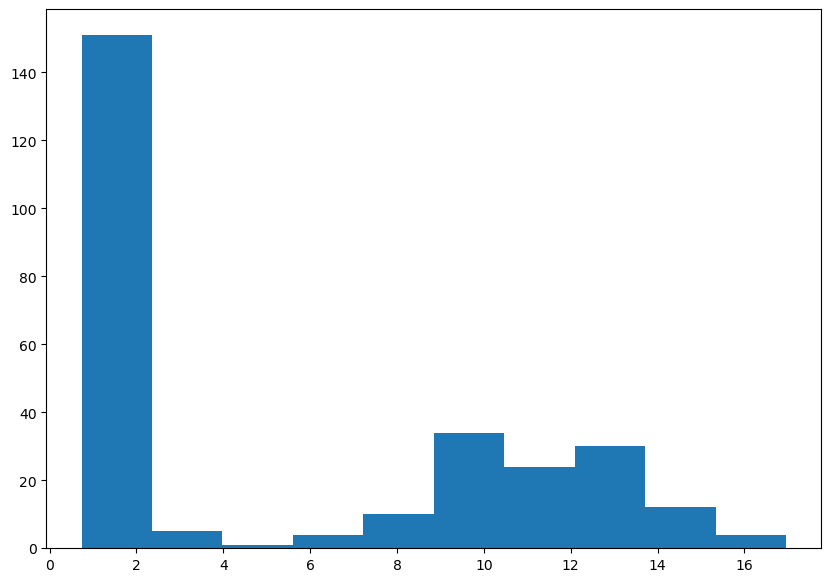

In [30]:
plt.hist(alllist_cut_w_sobel['sobel_ratio'])

In [32]:
reduced = rff.reduce_sobel(alllist_cut_w_sobel, 5)

Number of transient candidates reduced from 275 to 119.


image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.5


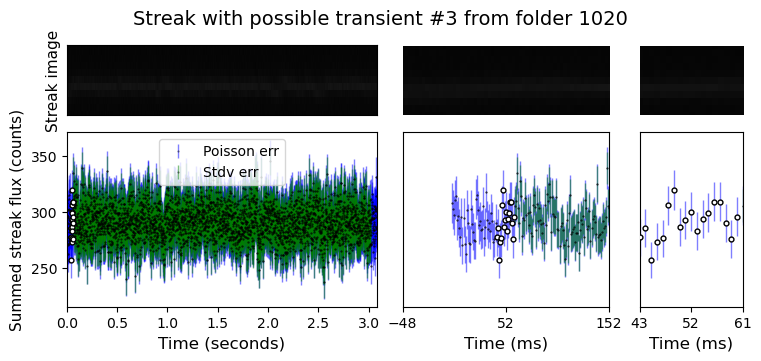

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.5


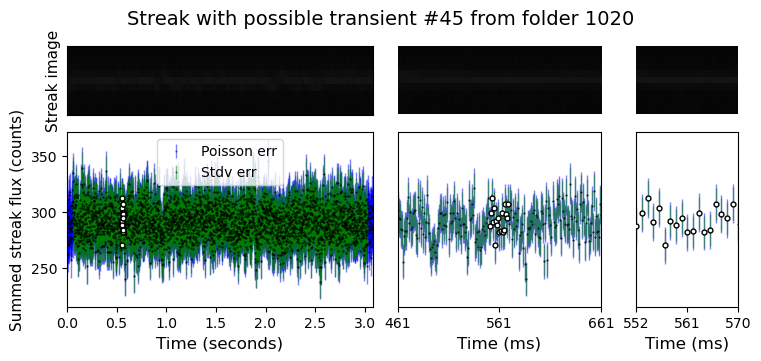

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.76923076923077


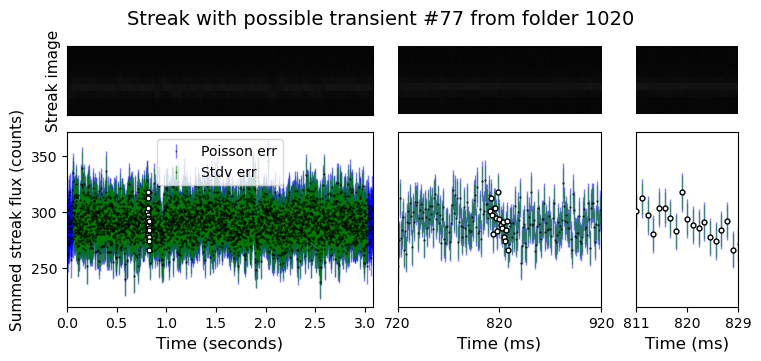

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.333333333333336


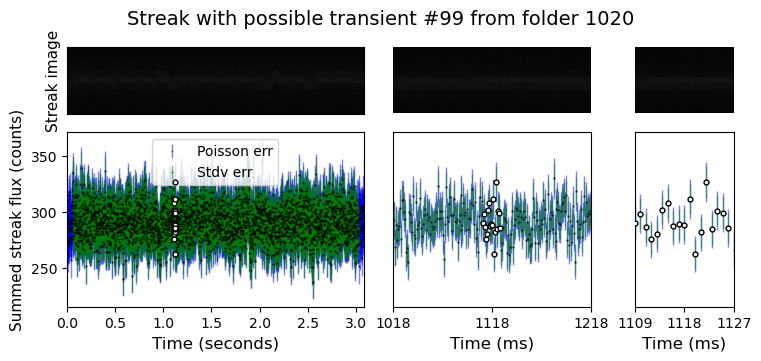

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.42307692307692


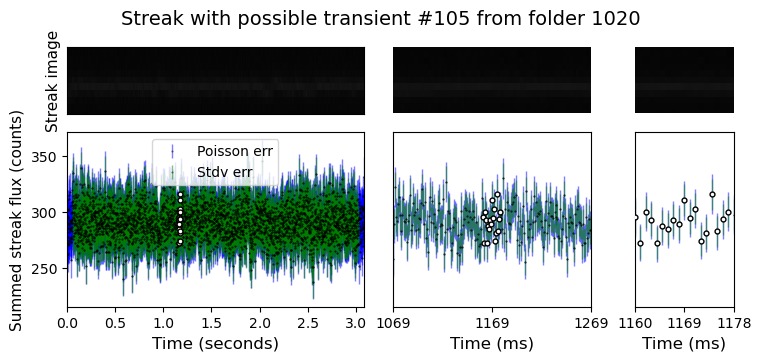

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.8


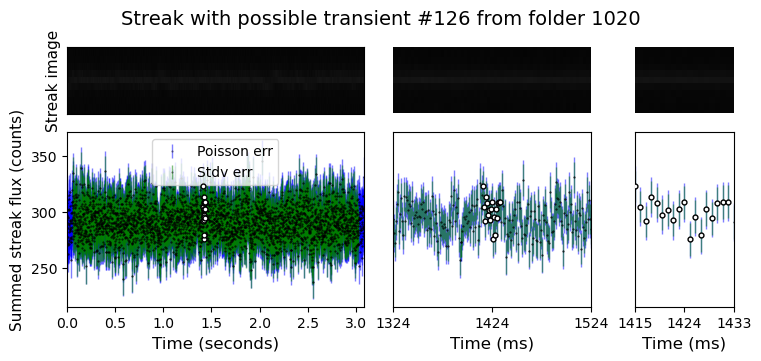

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.666666666666664


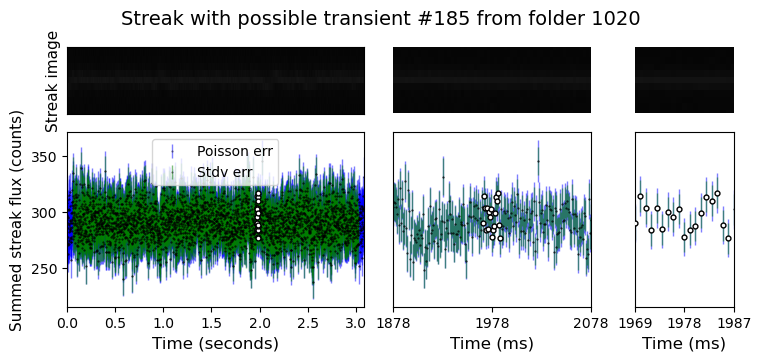

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.785714285714285


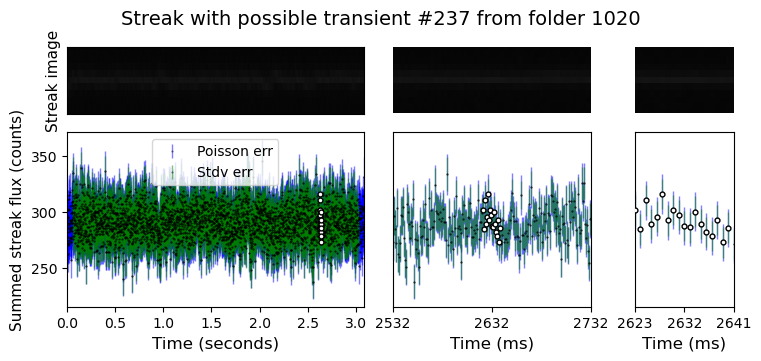

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.5


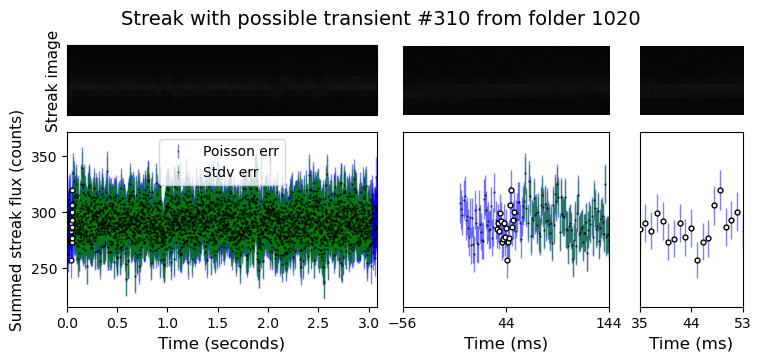

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.13513513513514


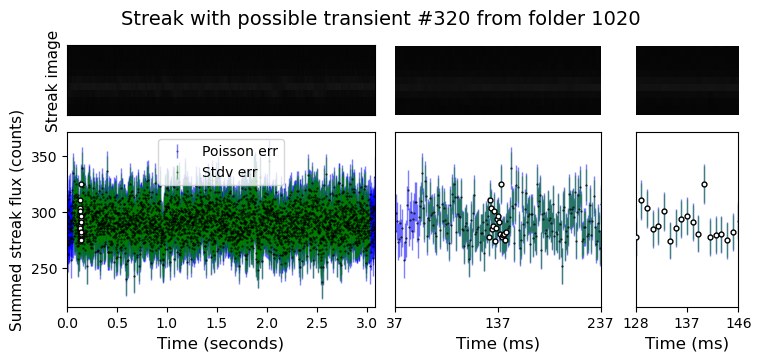

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  35.13333333333333


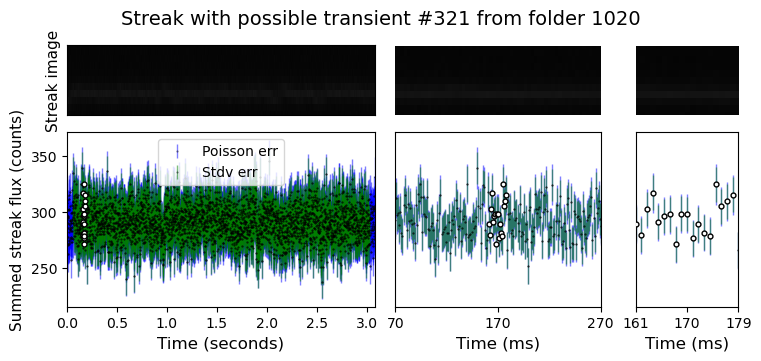

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  35.333333333333336


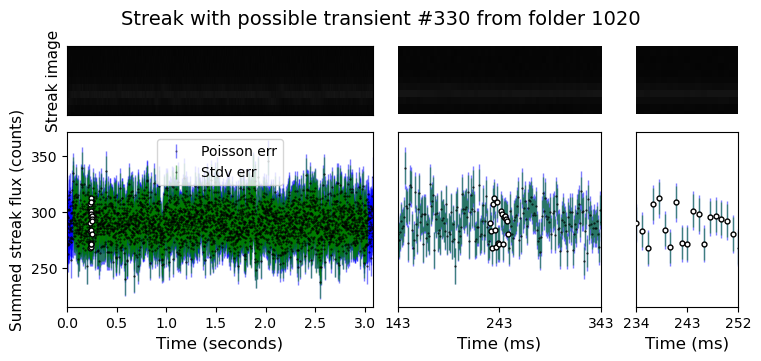

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.916666666666664


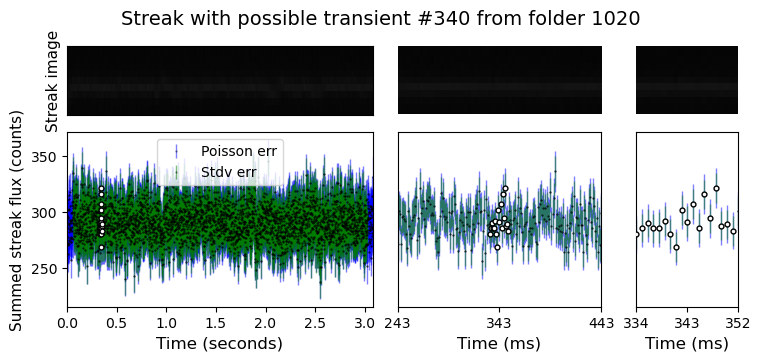

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.7


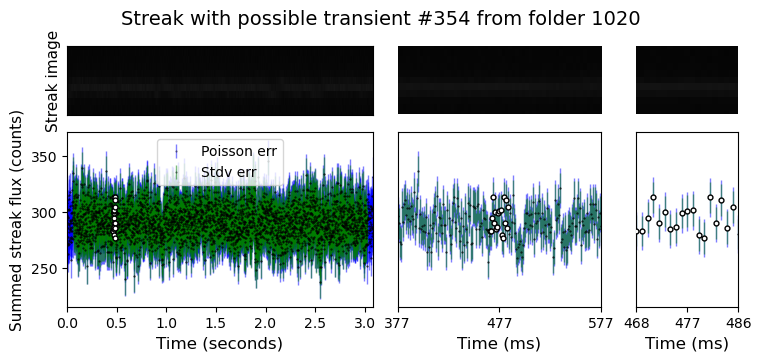

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.45454545454545


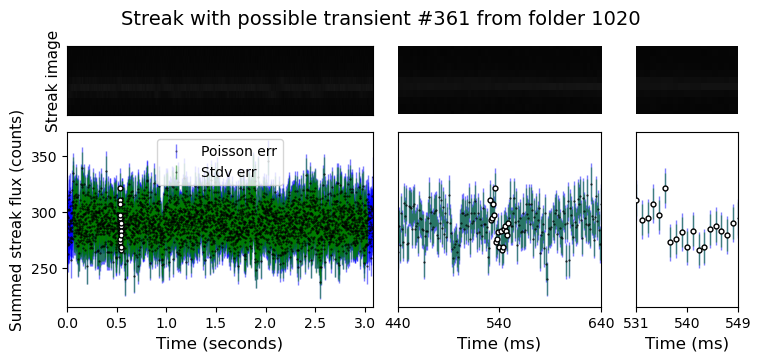

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.375


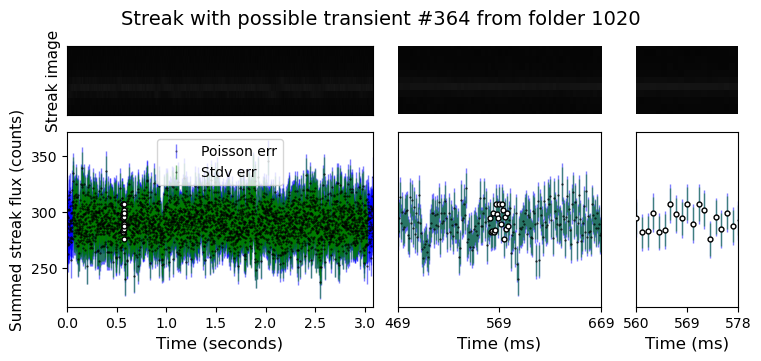

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.5


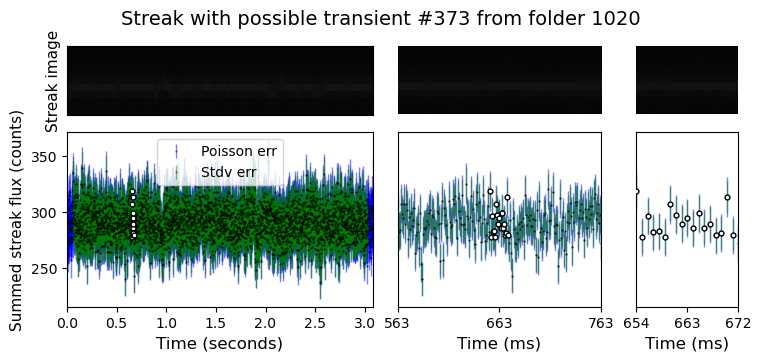

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.785714285714285


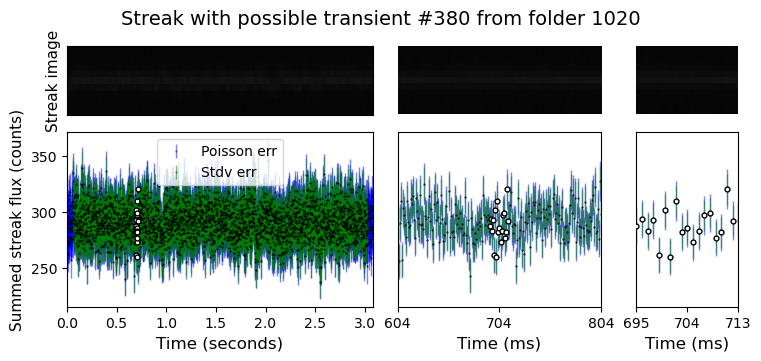

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.8


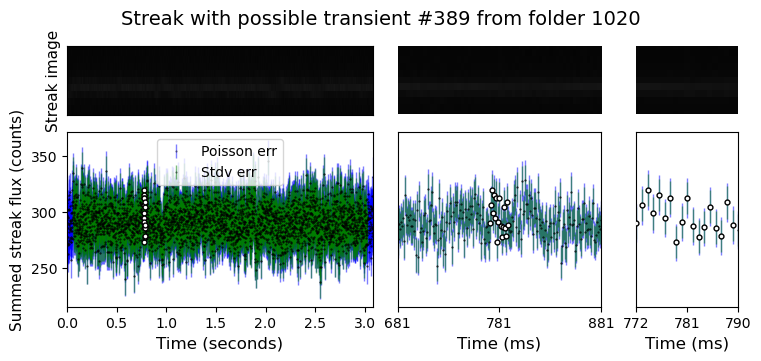

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.857142857142854


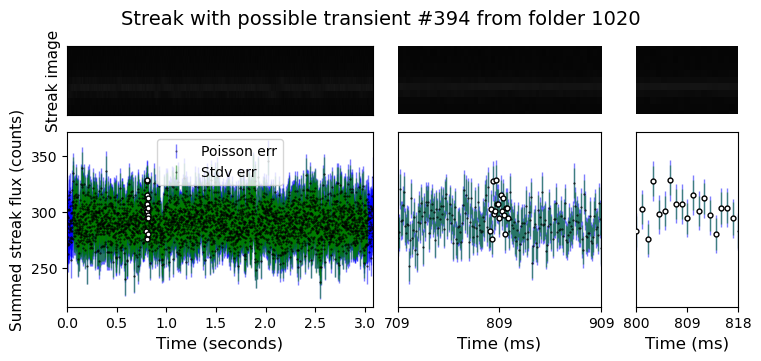

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.111111111111114


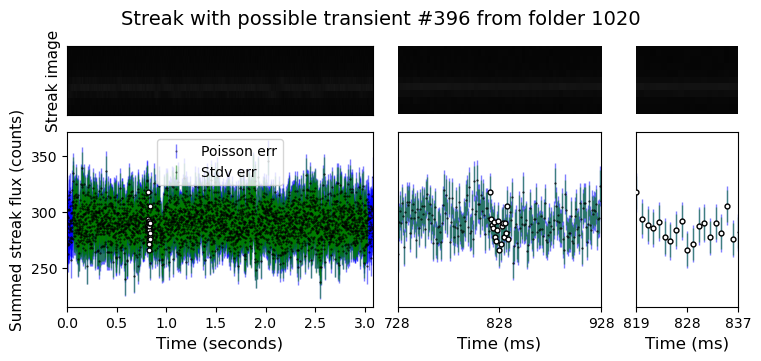

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  35.92857142857143


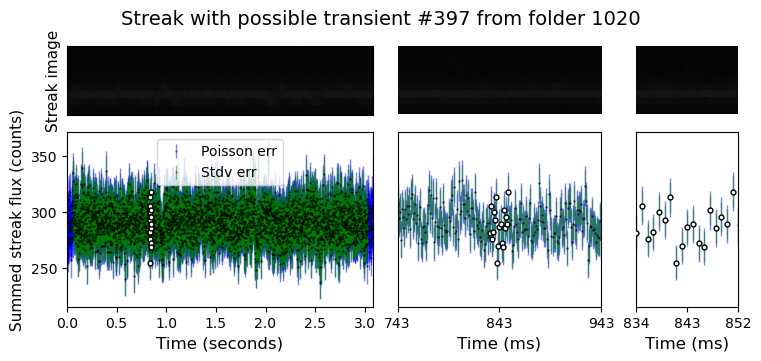

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  35.1578947368421


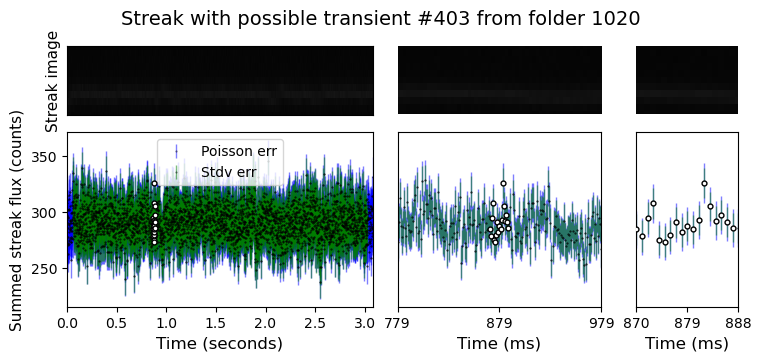

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.86666666666667


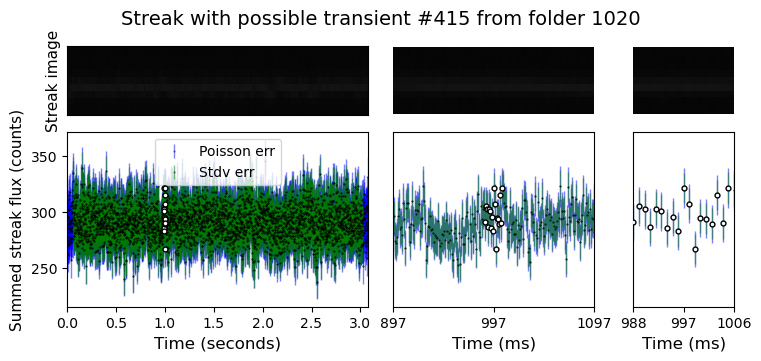

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.94117647058823


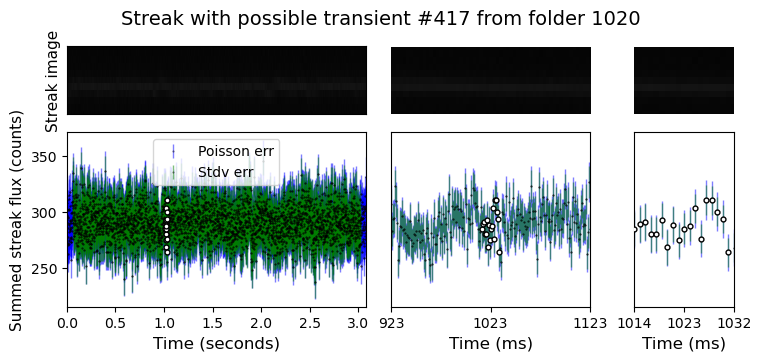

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.27777777777778


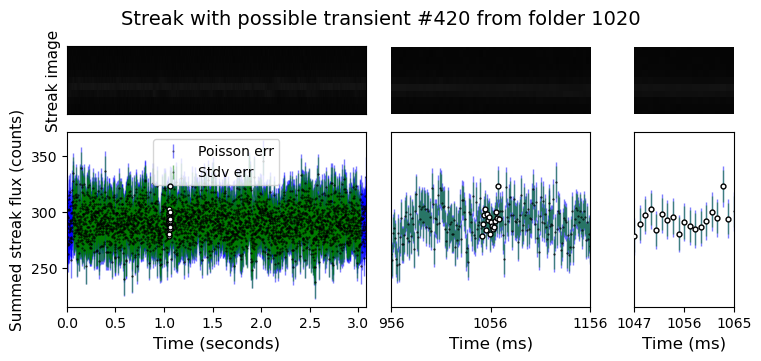

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.90909090909091


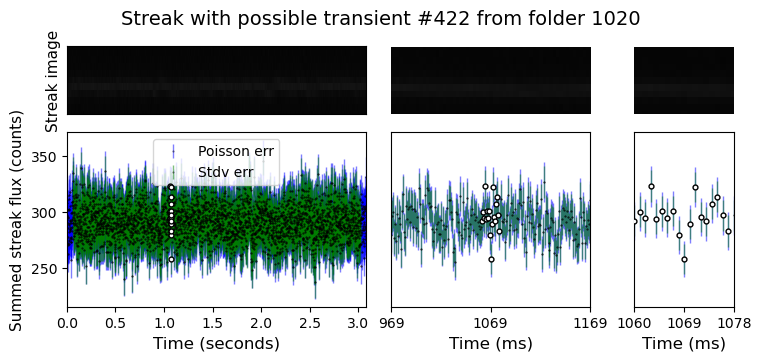

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.733333333333334


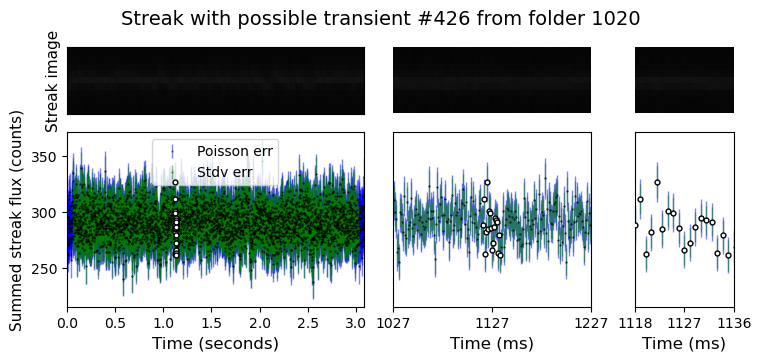

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.411764705882355


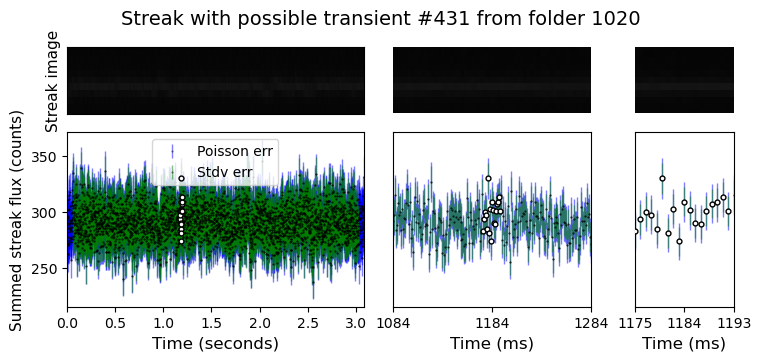

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.21052631578947


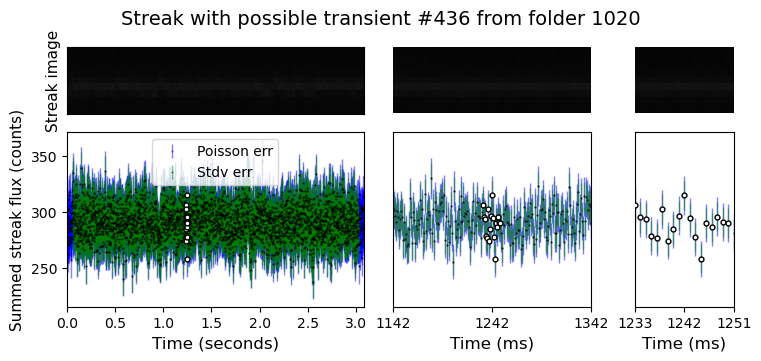

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.36842105263158


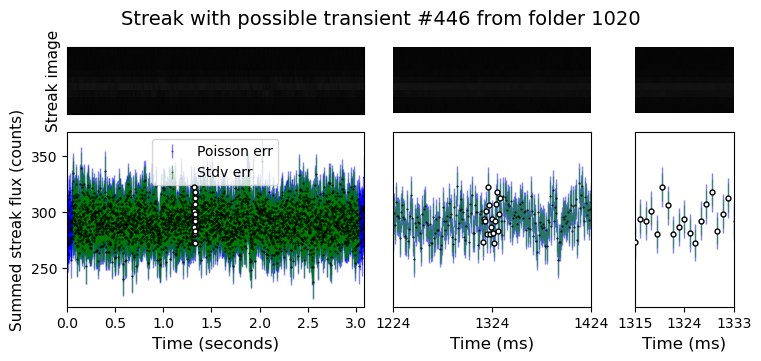

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.61538461538461


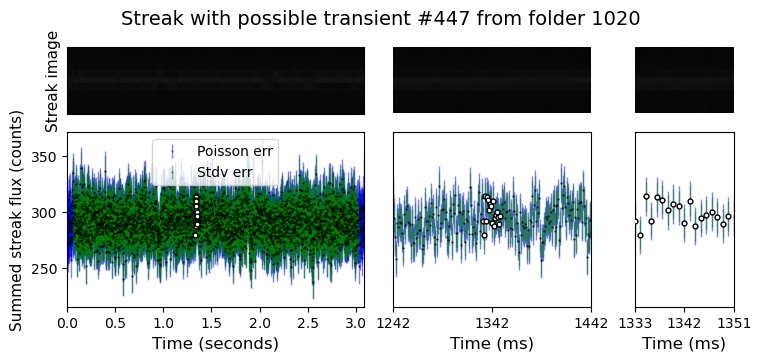

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.41935483870968


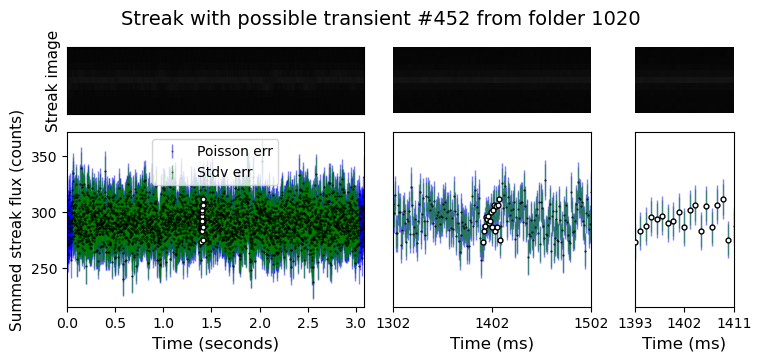

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.083333333333336


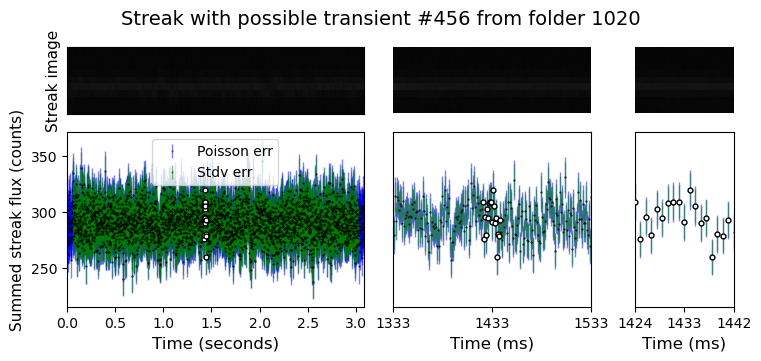

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.07142857142857


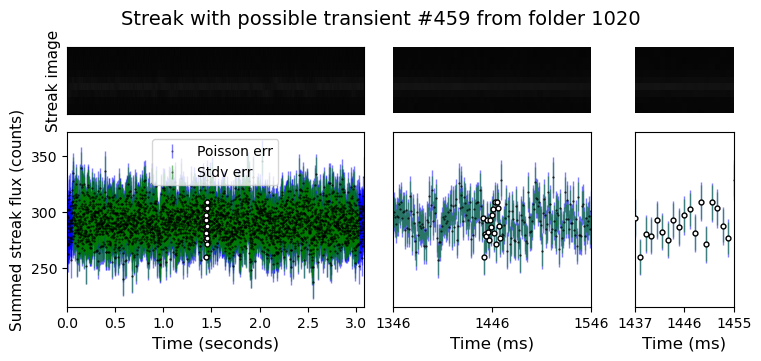

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.142857142857146


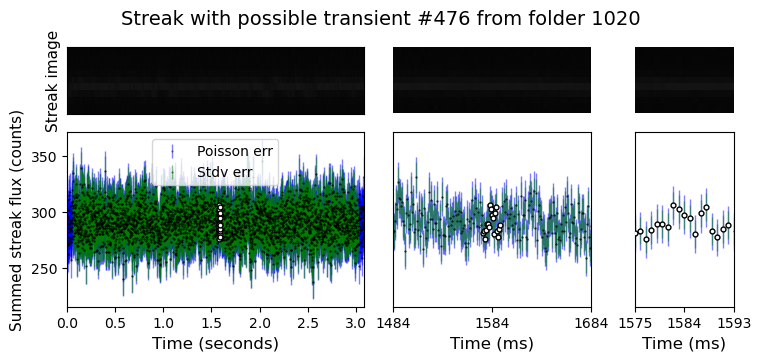

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.9375


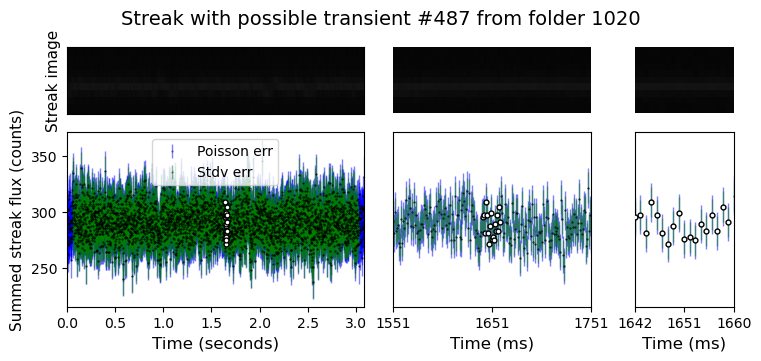

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  1889.0816326530608


/home/3155/review_findings_functions.py:574: RuntimeWarning: invalid value encountered in sqrt
  sqrt = np.sqrt(tot)


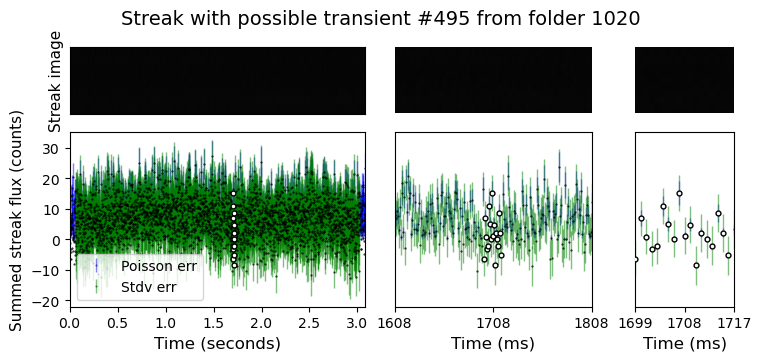

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.416666666666664


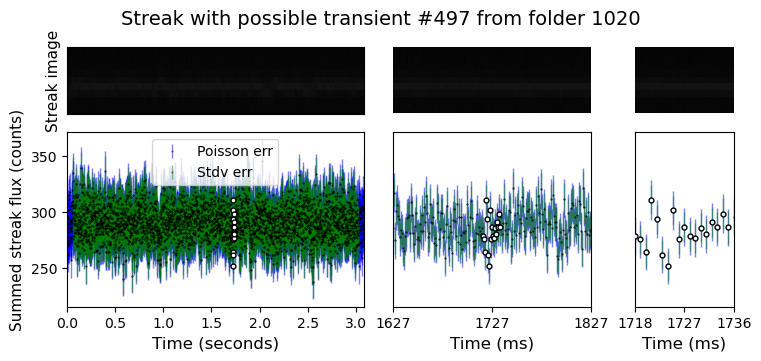

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.96774193548387


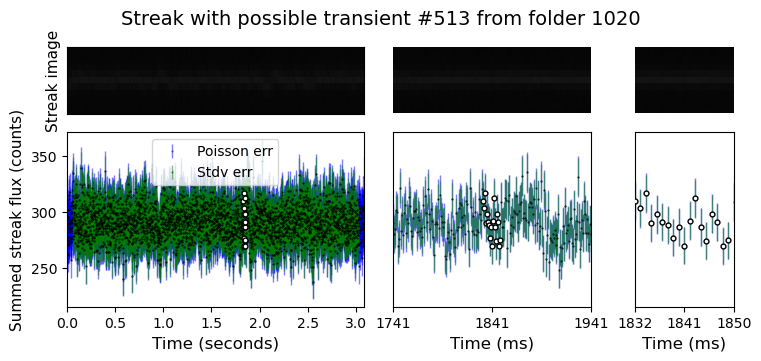

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.714285714285715


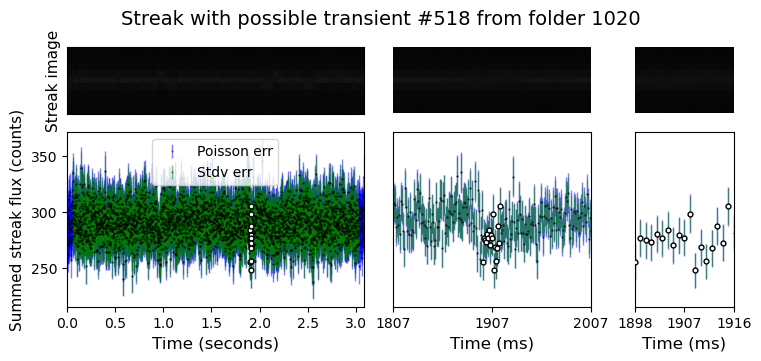

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.68421052631579


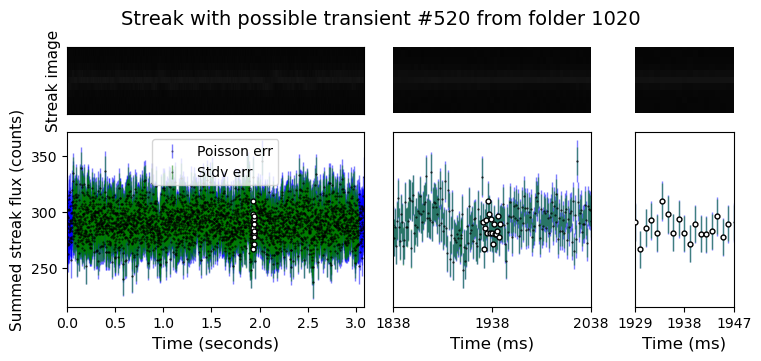

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.75


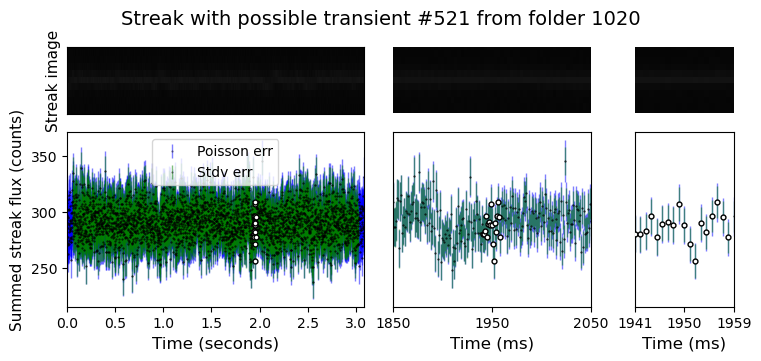

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.53333333333333


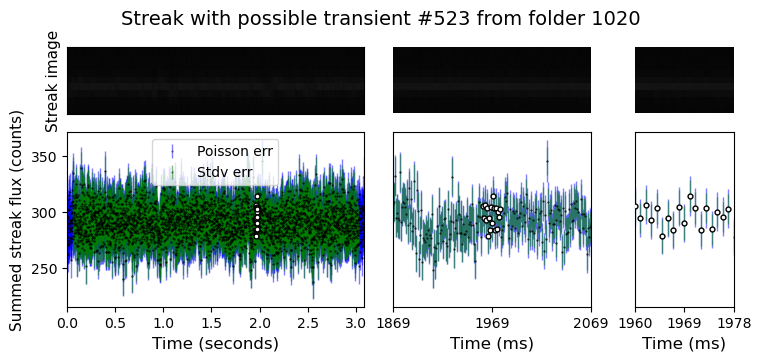

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  35.0


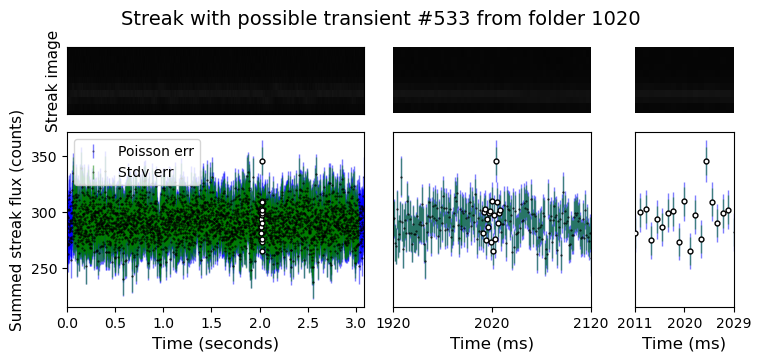

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.75


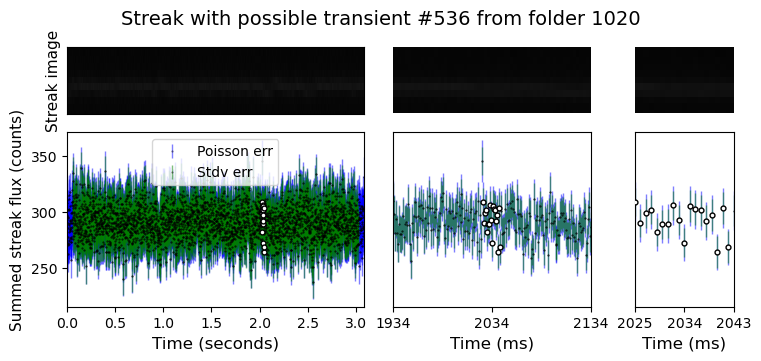

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.5


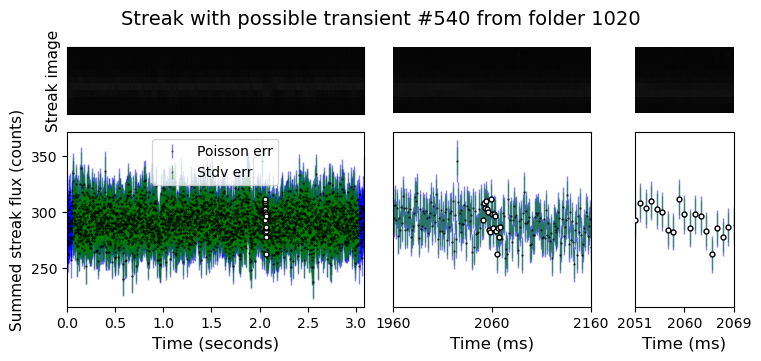

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.81818181818182


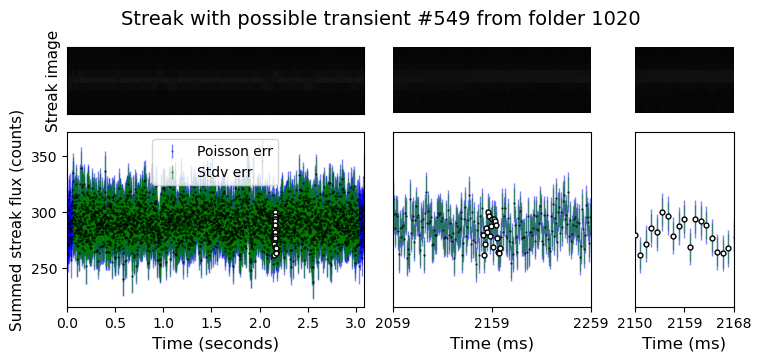

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.92307692307692


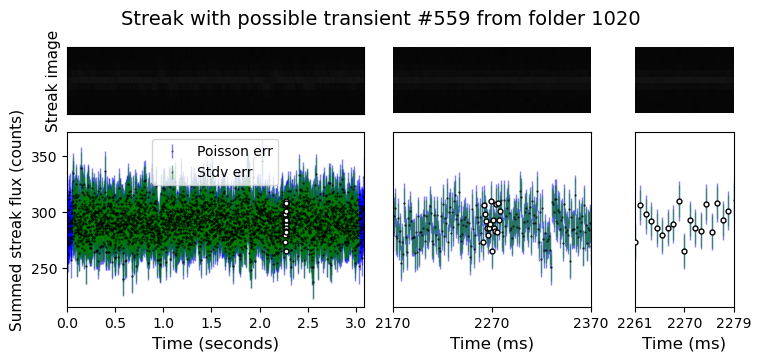

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.791666666666664


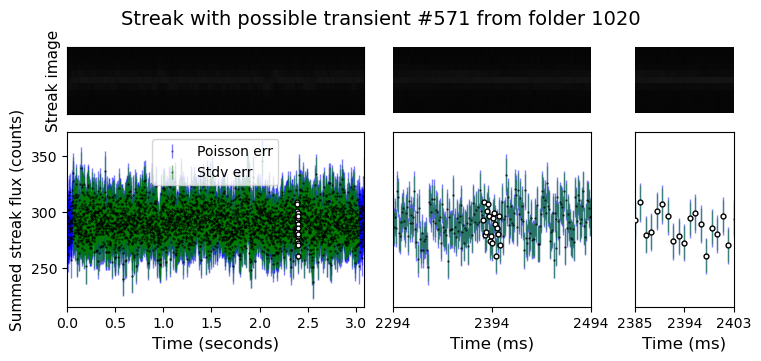

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.10344827586207


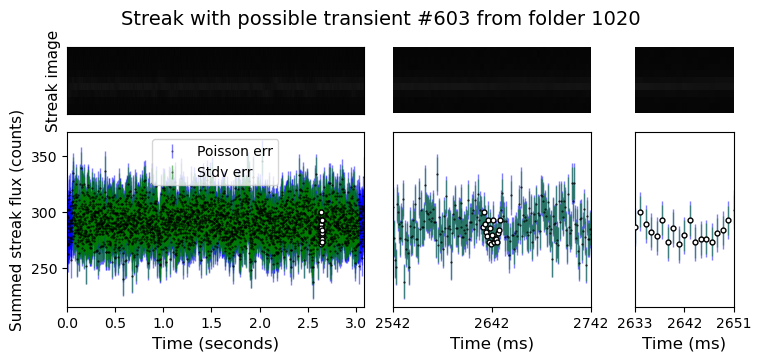

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.8421052631579


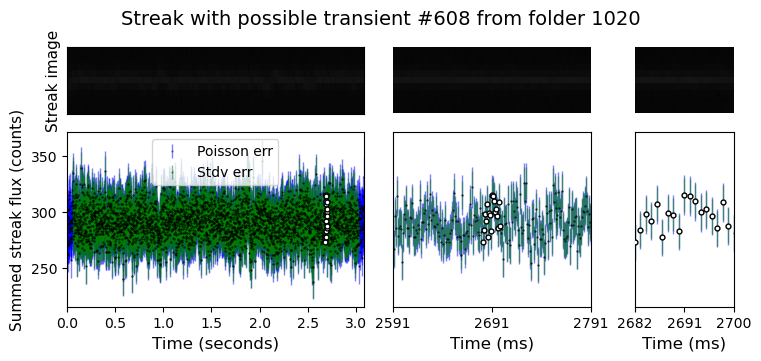

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.625


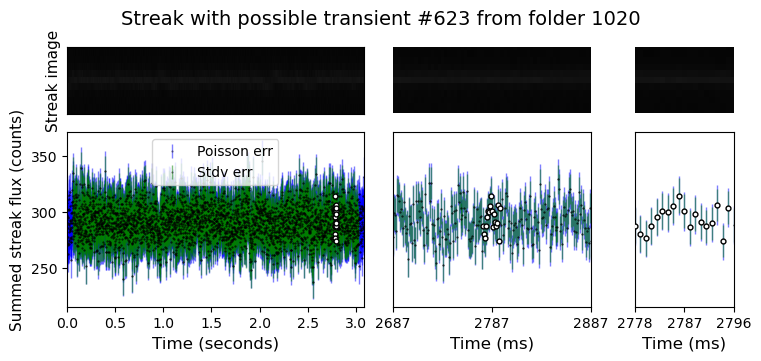

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.27272727272727


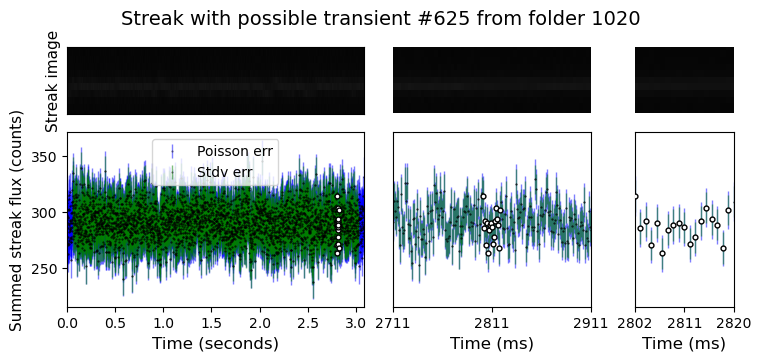

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.95454545454545


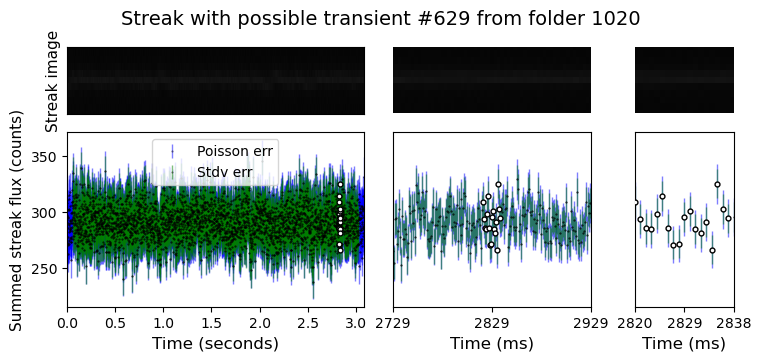

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.36842105263158


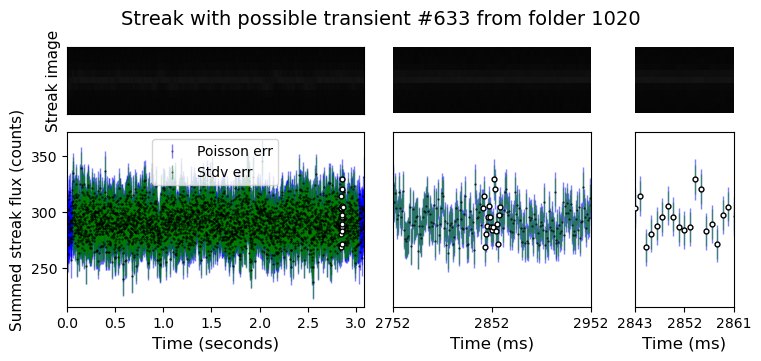

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.04


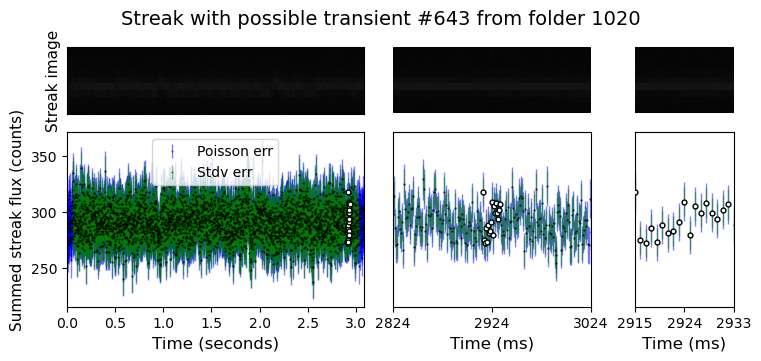

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.36363636363637


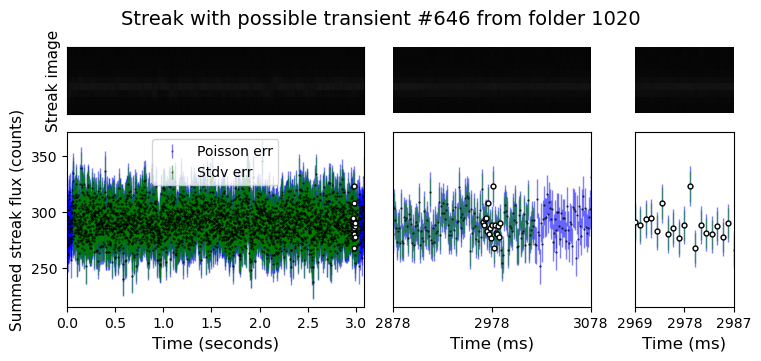

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.94117647058823


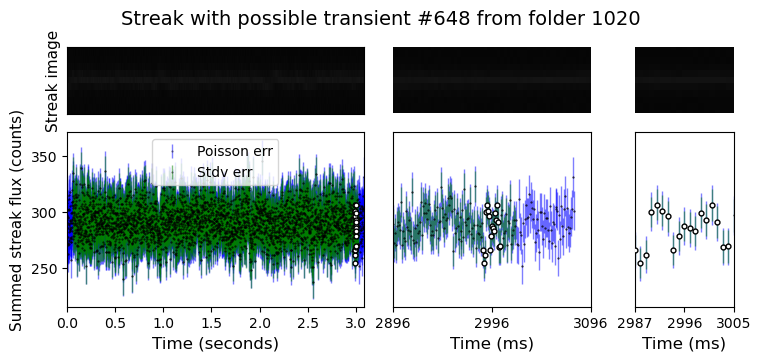

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.45454545454545


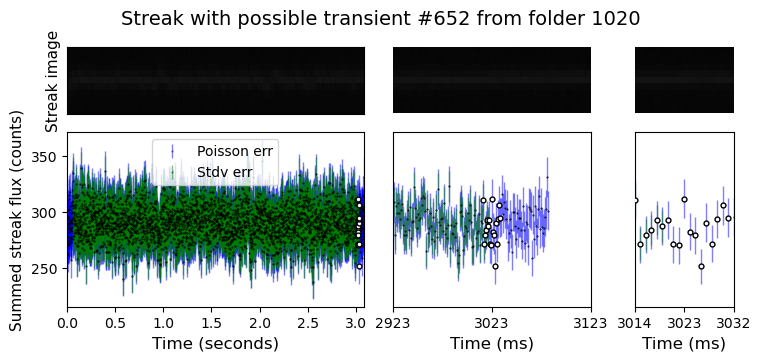

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.5


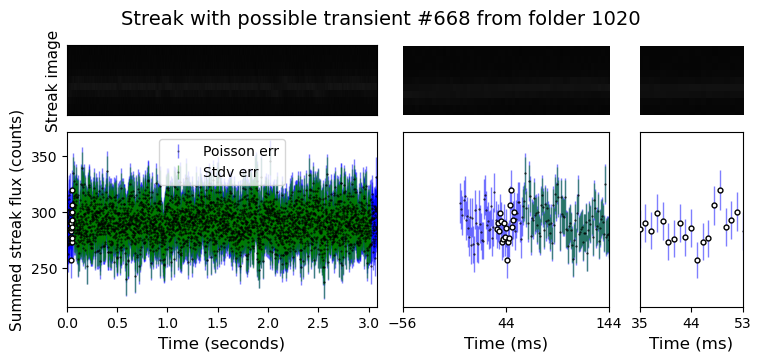

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.5


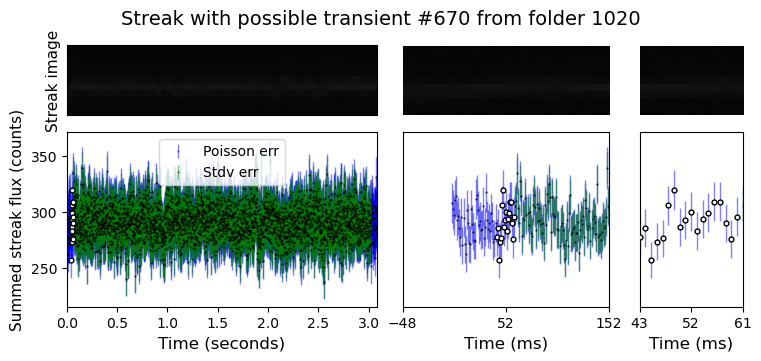

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.13513513513514


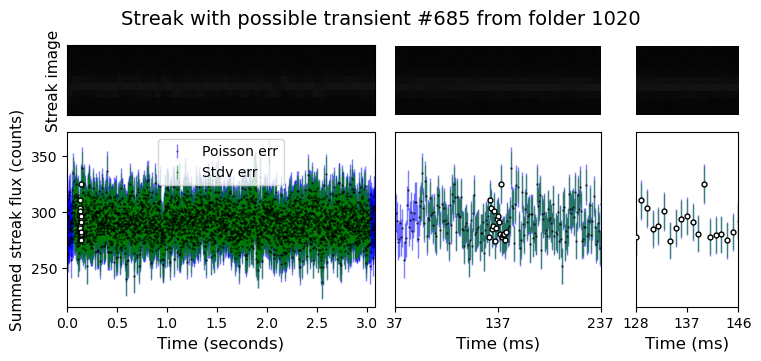

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  35.13333333333333


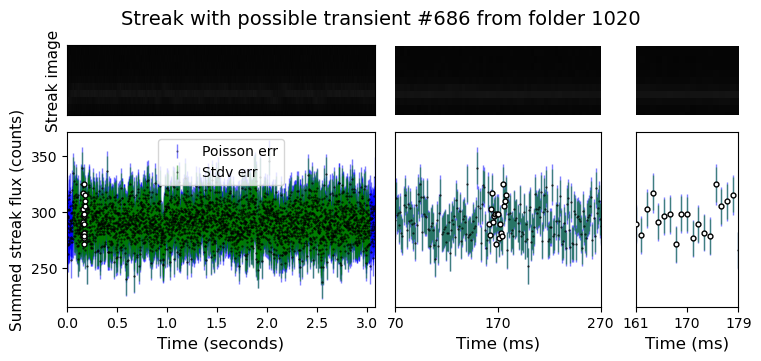

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  35.333333333333336


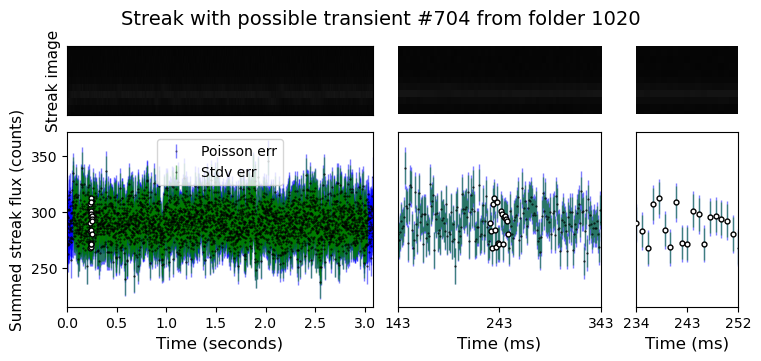

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.916666666666664


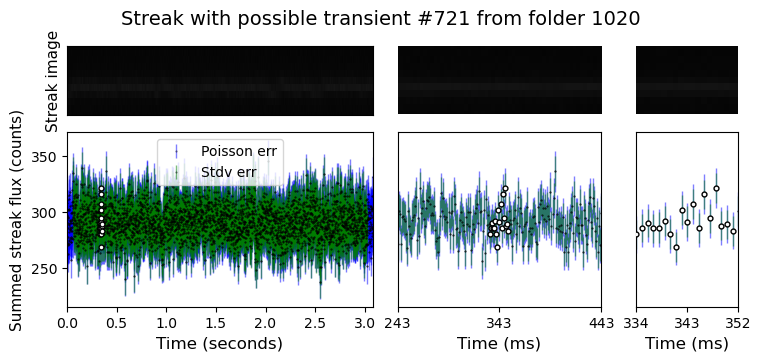

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.7


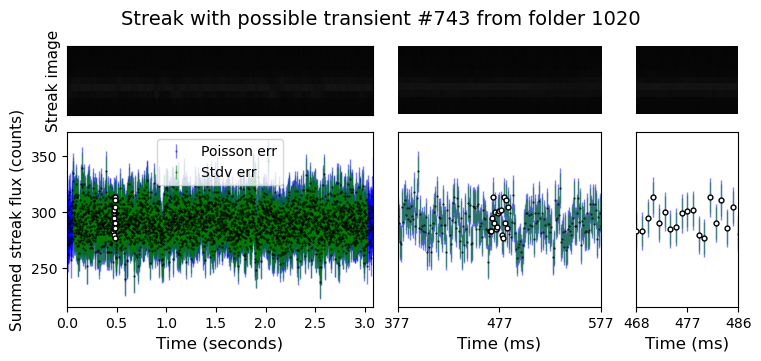

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.45454545454545


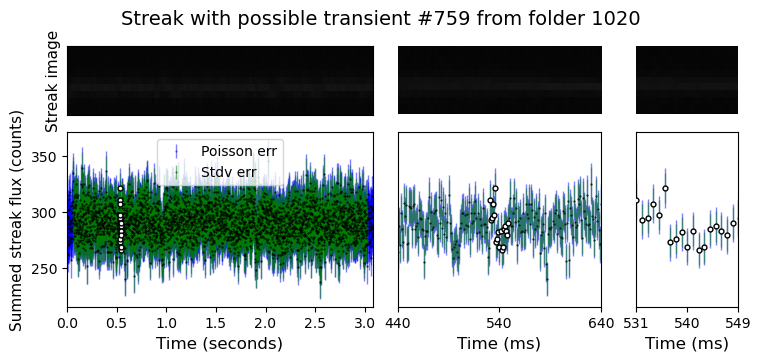

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.5


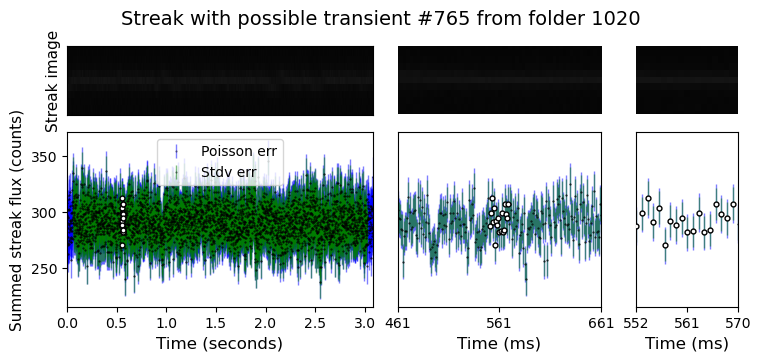

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.375


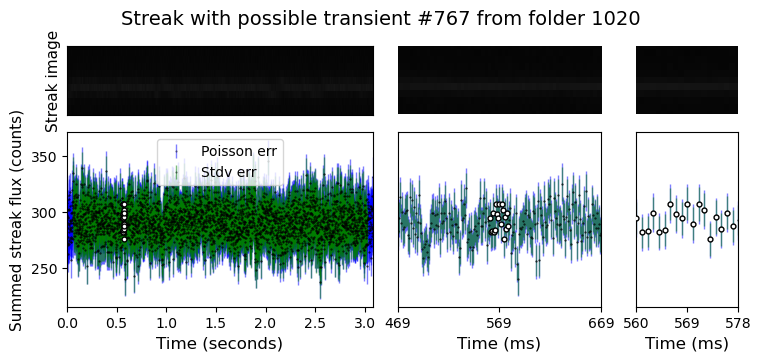

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.5


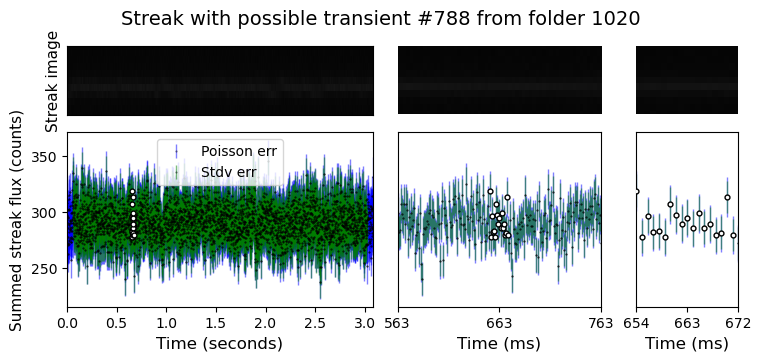

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.785714285714285


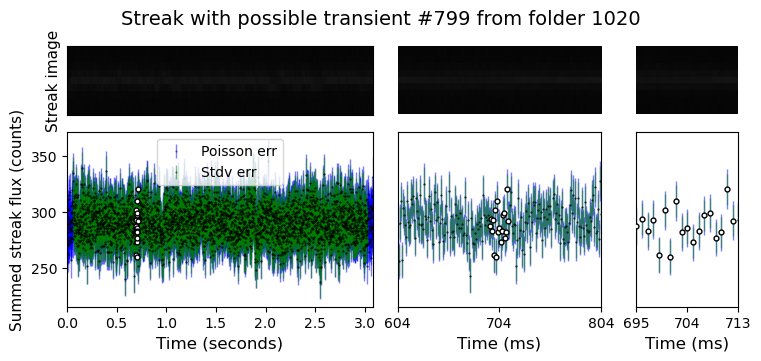

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.8


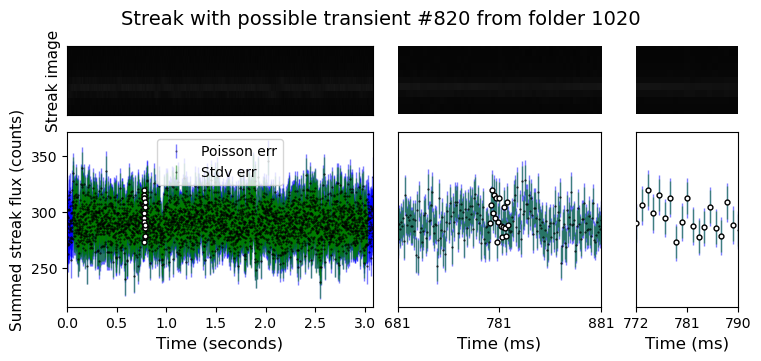

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.857142857142854


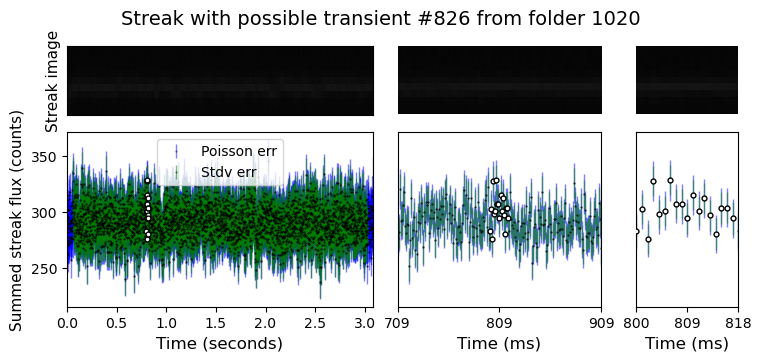

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.76923076923077


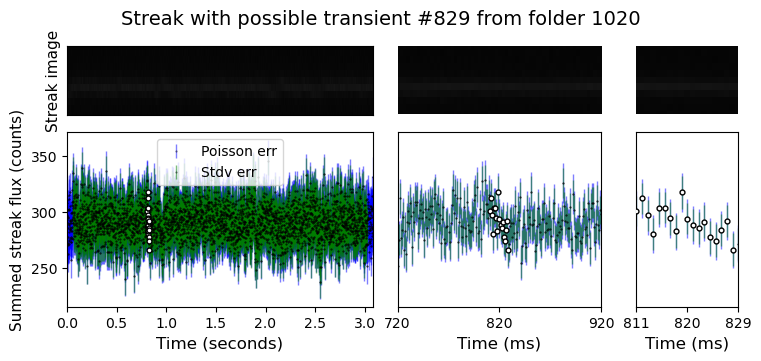

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.111111111111114


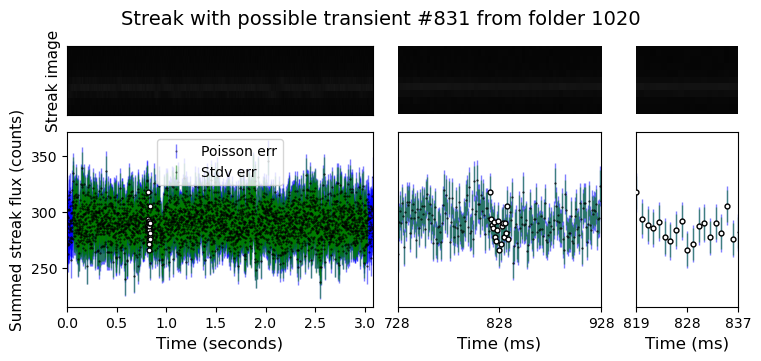

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  35.92857142857143


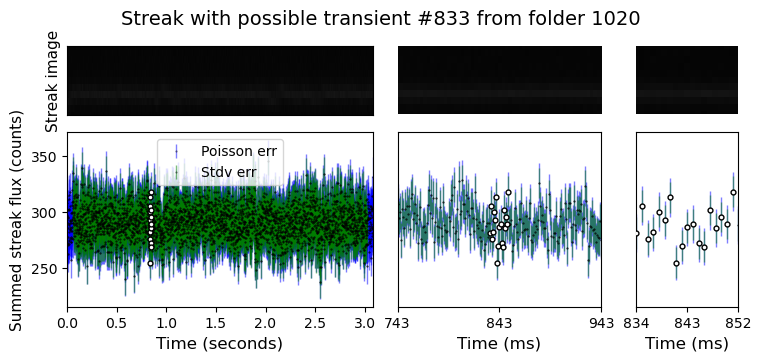

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  35.1578947368421


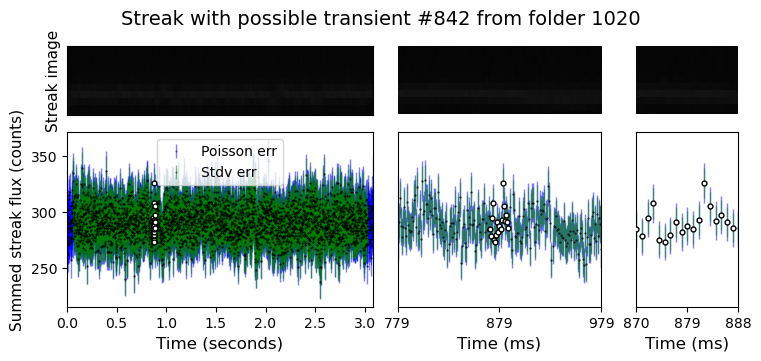

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.86666666666667


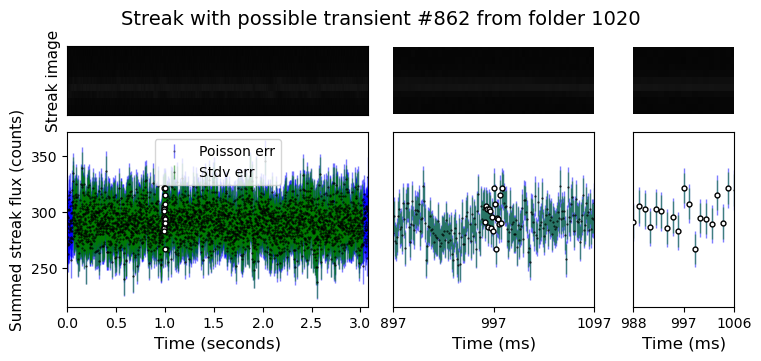

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.94117647058823


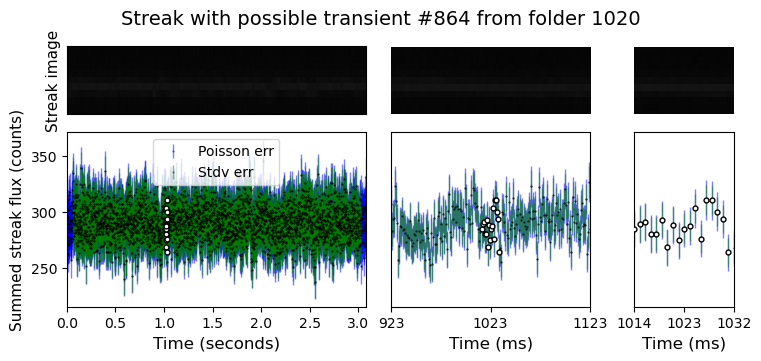

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.27777777777778


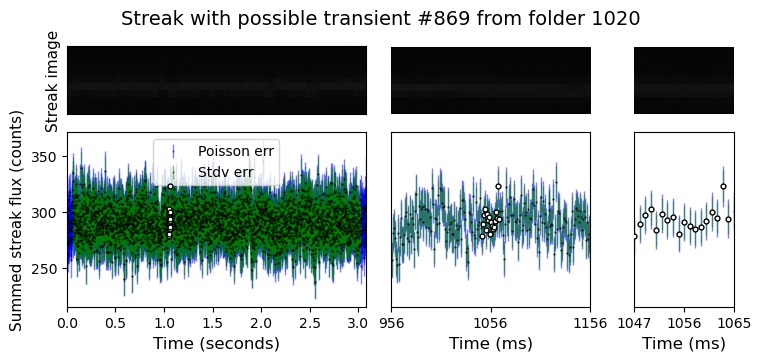

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.90909090909091


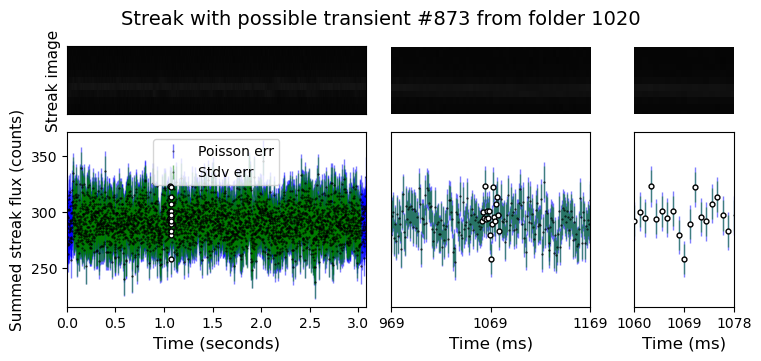

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.333333333333336


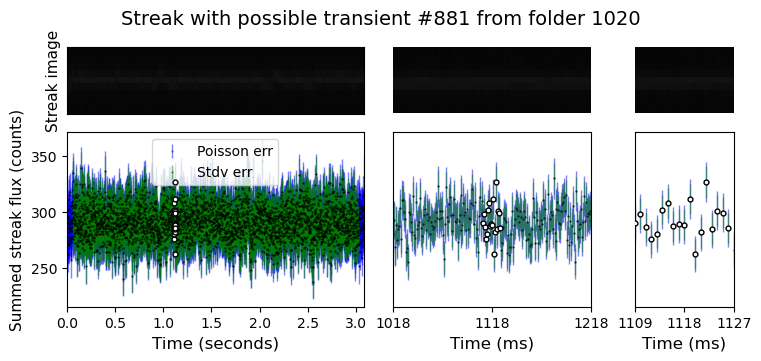

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.733333333333334


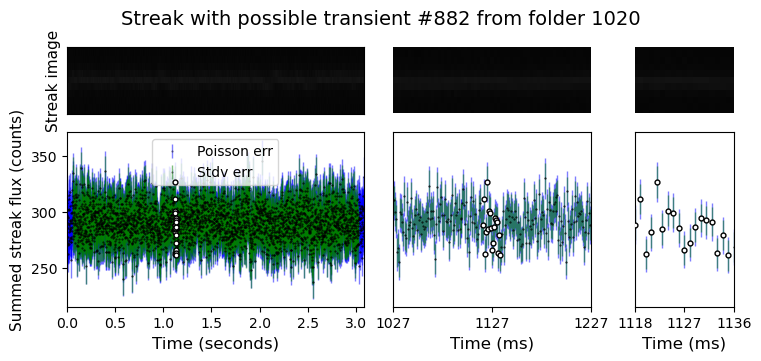

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.42307692307692


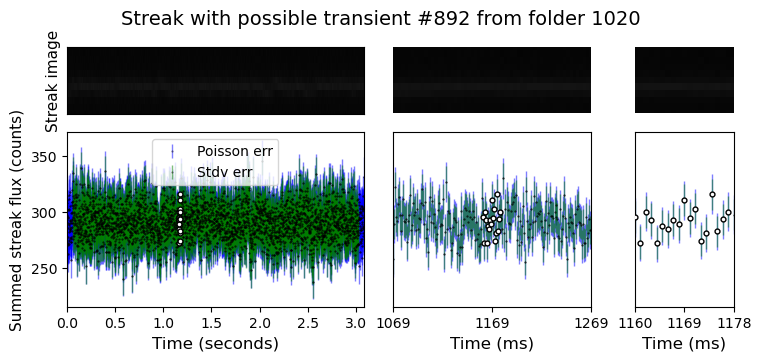

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.411764705882355


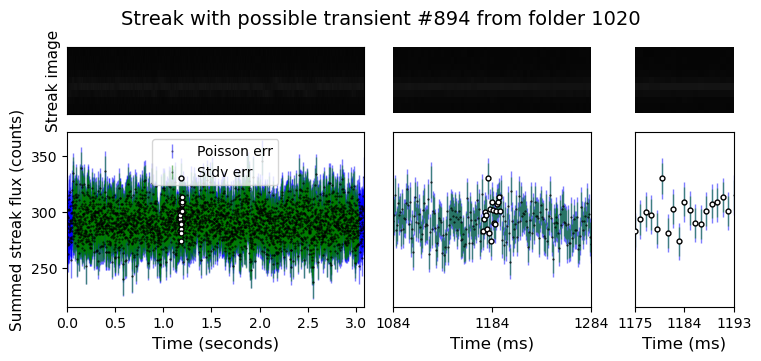

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.21052631578947


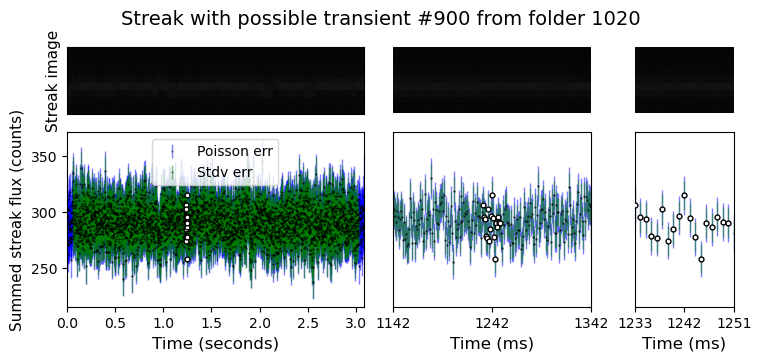

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.36842105263158


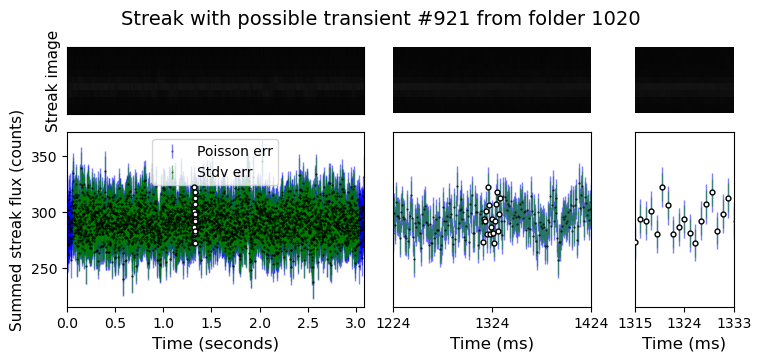

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.61538461538461


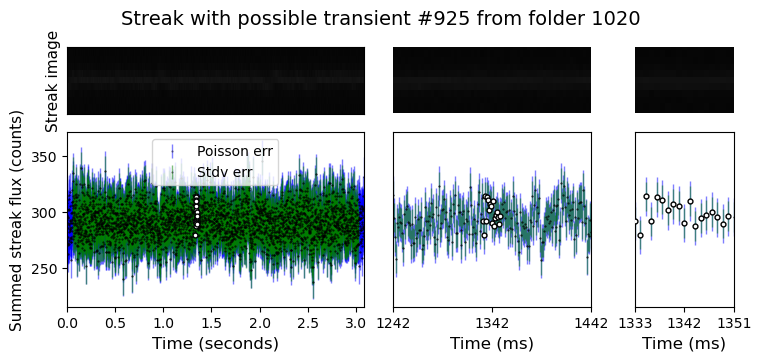

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.41935483870968


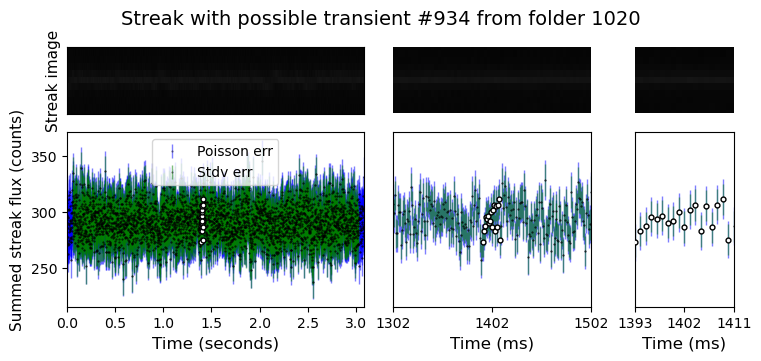

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.8


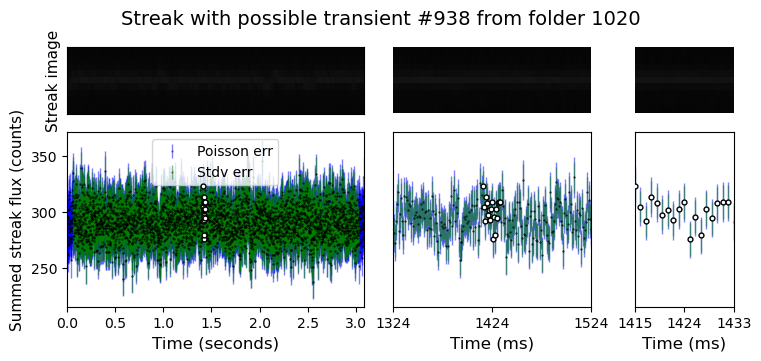

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.083333333333336


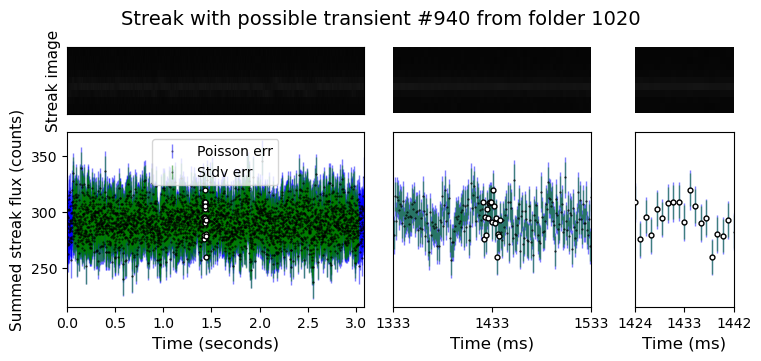

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.07142857142857


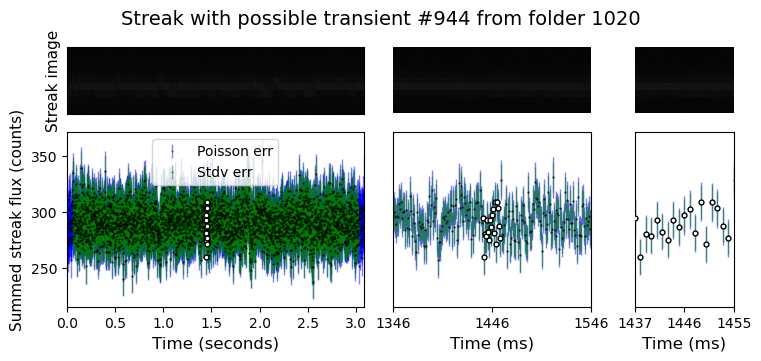

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.142857142857146


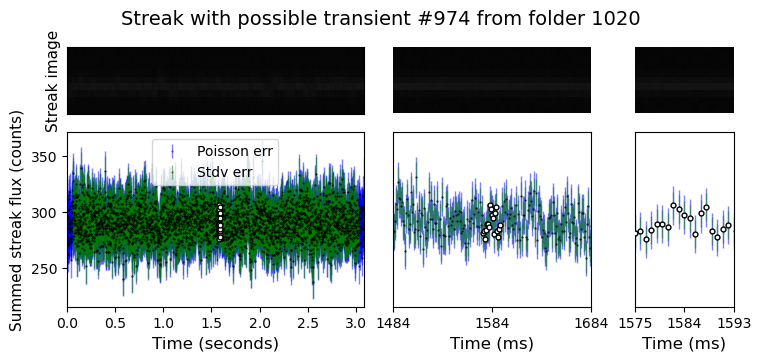

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.9375


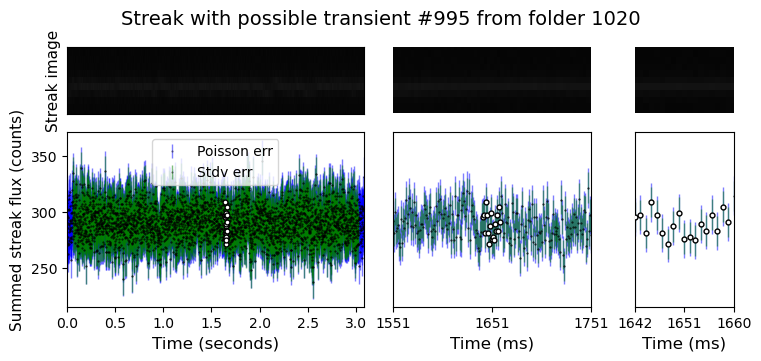

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.416666666666664


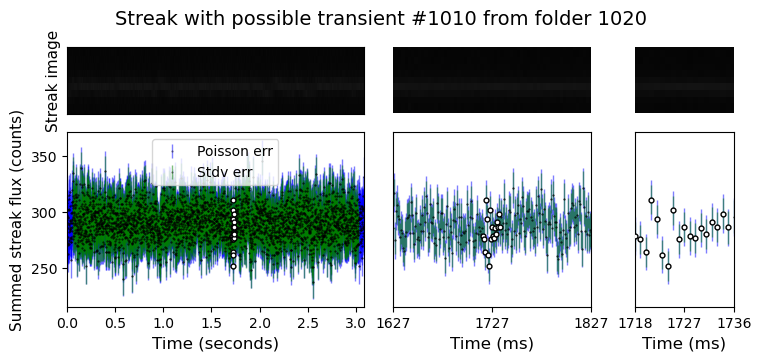

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.96774193548387


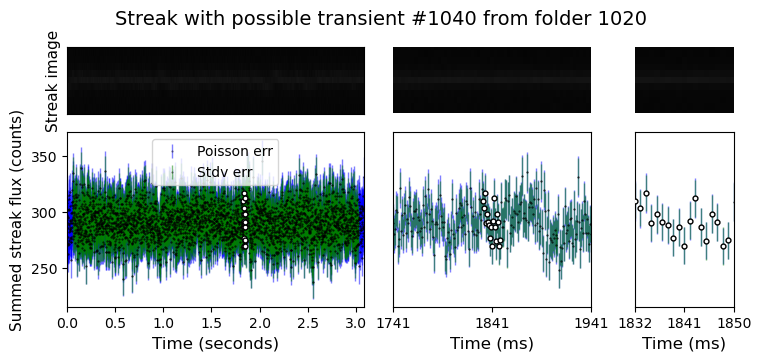

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.714285714285715


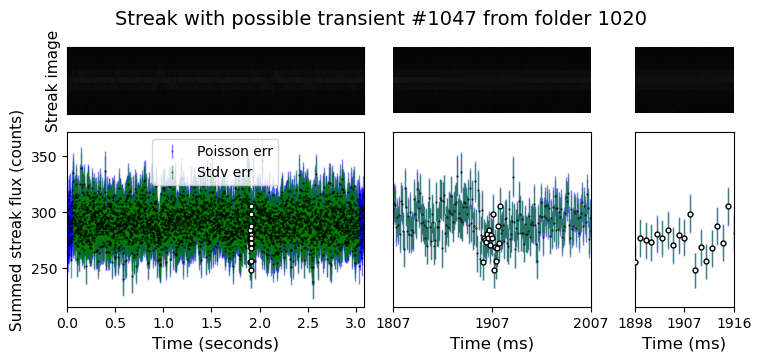

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.68421052631579


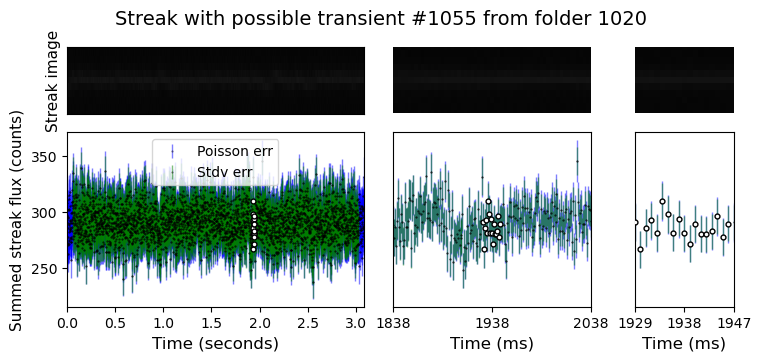

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.75


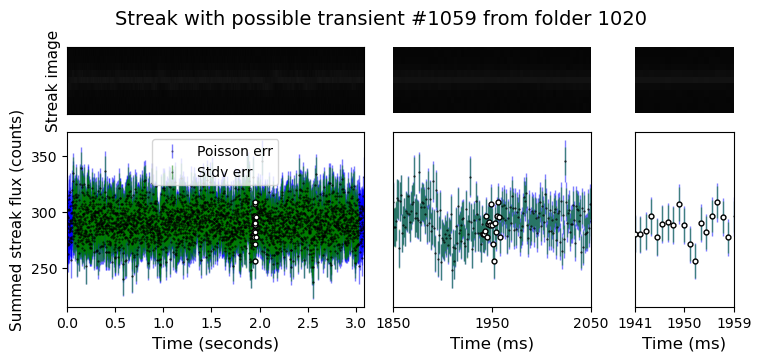

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.53333333333333


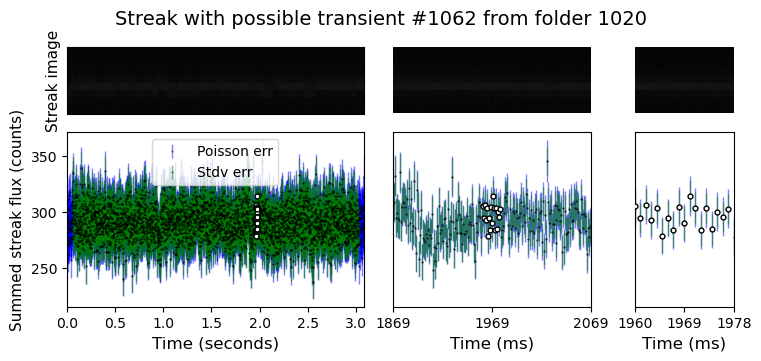

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.666666666666664


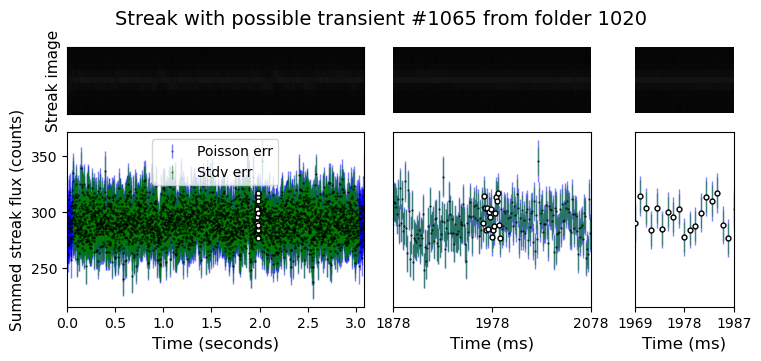

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  35.0


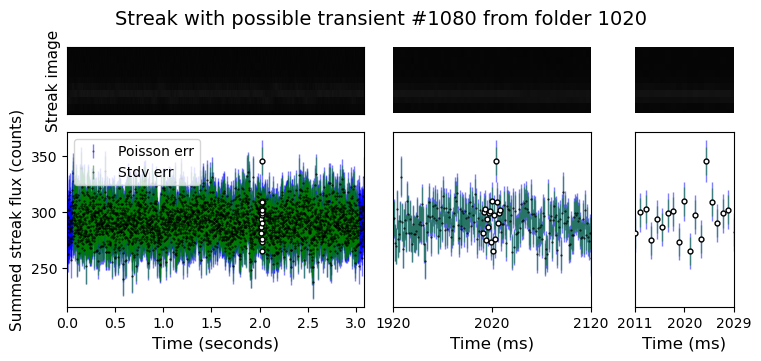

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.75


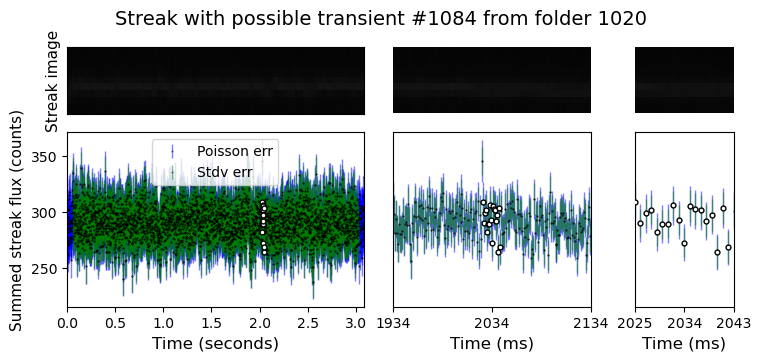

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.5


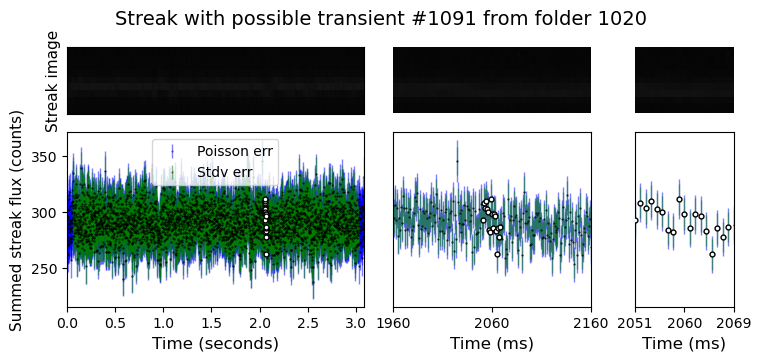

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.81818181818182


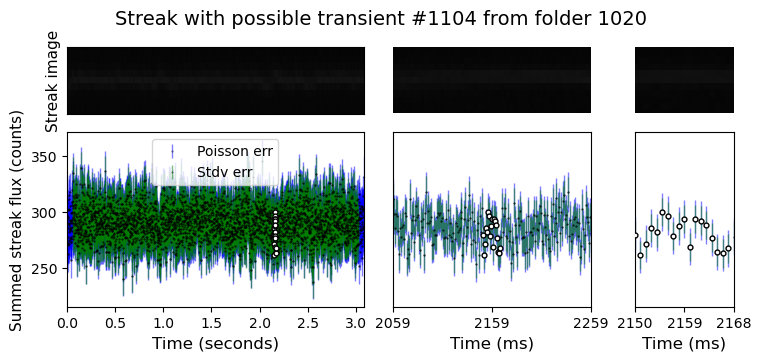

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.92307692307692


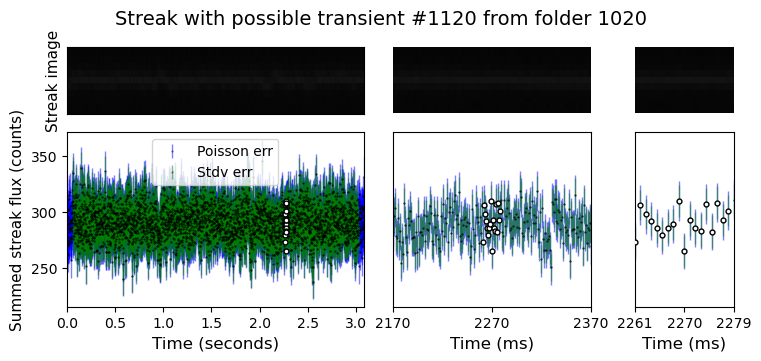

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.791666666666664


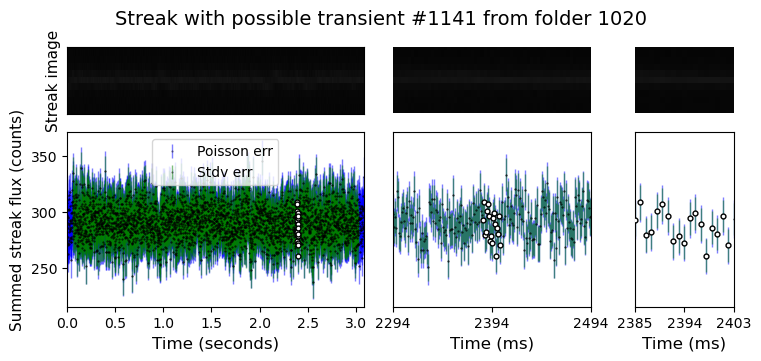

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.785714285714285


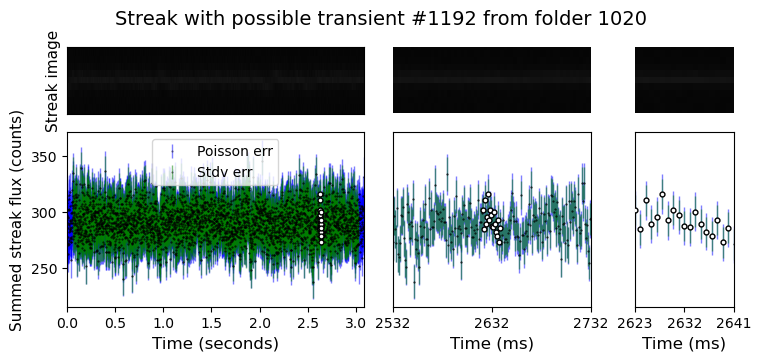

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.10344827586207


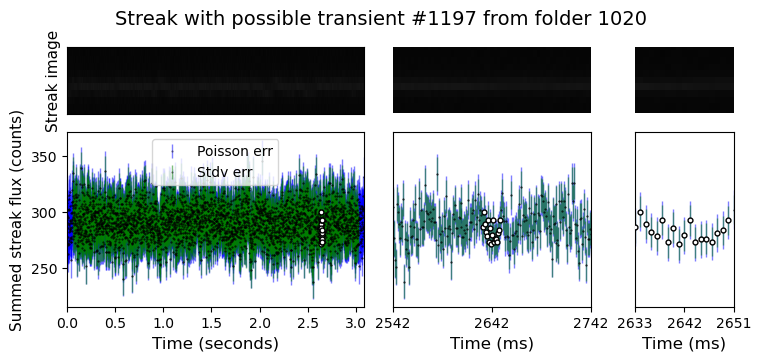

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.8421052631579


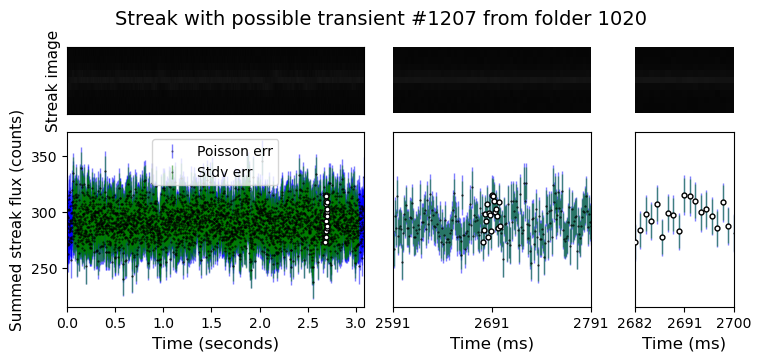

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.625


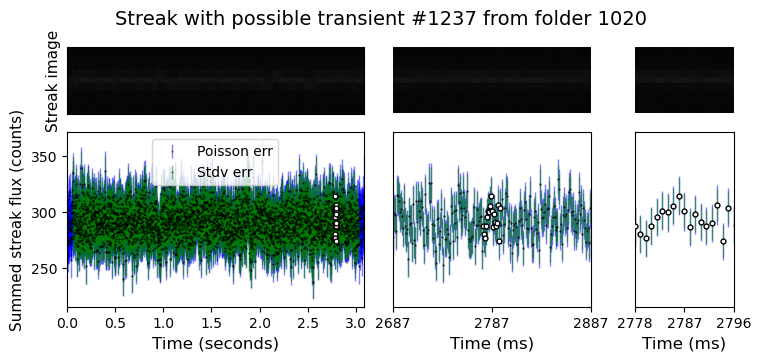

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.27272727272727


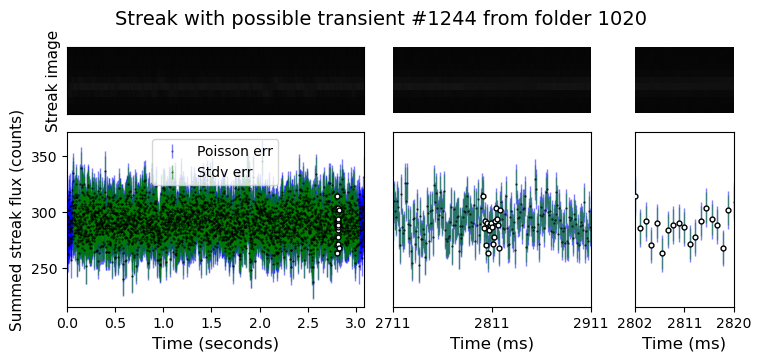

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.95454545454545


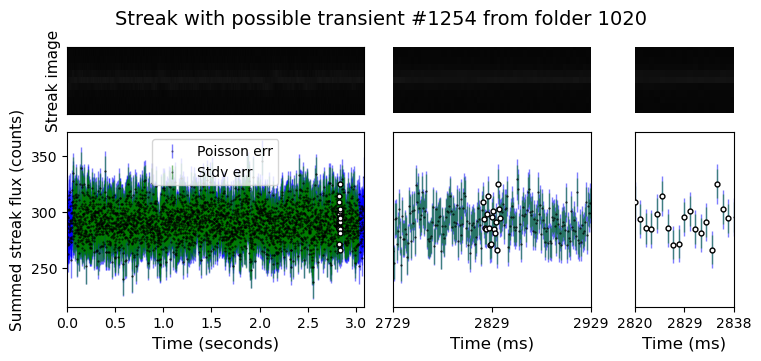

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.36842105263158


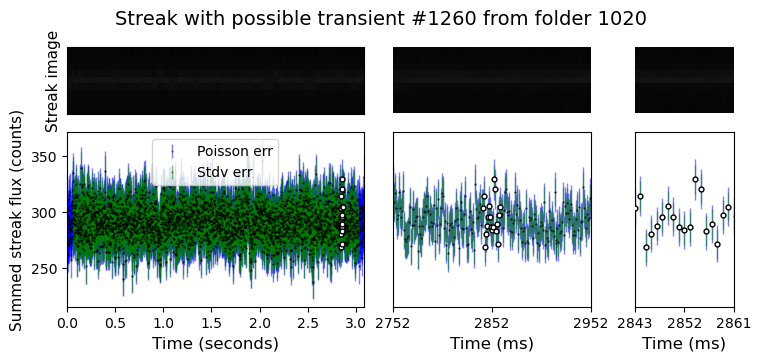

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.04


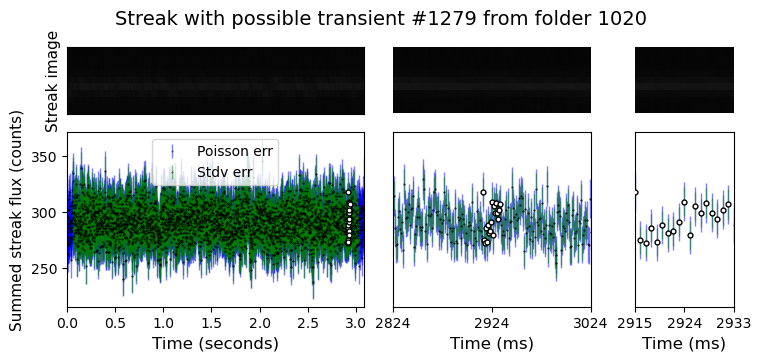

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  34.36363636363637


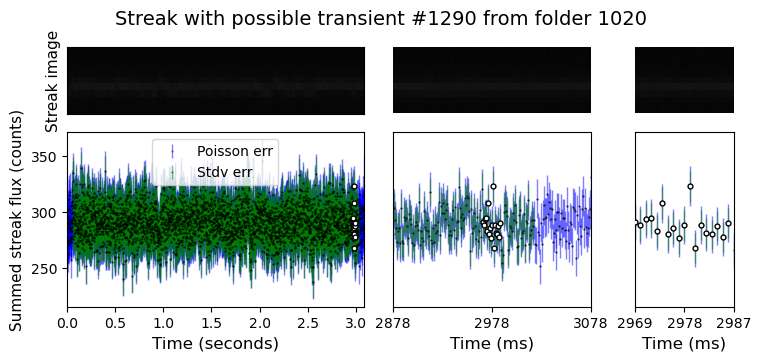

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.94117647058823


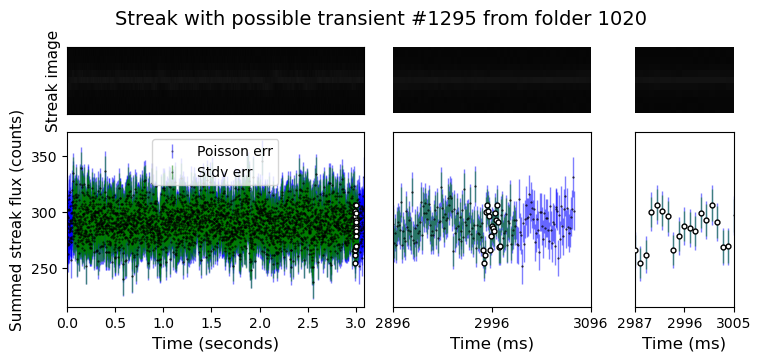

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.45454545454545


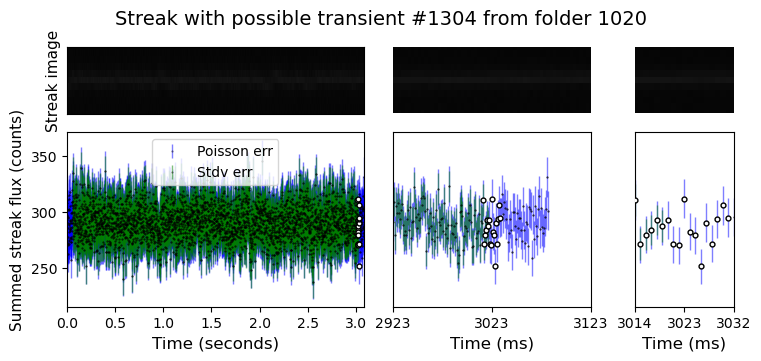

In [36]:
rff.inspect_df_time_series(reduced, alllist, '1020', start=0, stop=len(reduced))

In [45]:
crs = alllist[alllist['type'] == 'cr']

In [46]:
len(crs)

0

In [48]:
alllist[alllist['type'] == 'cr']

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size


In [52]:
alllist_stdv = rff.add_stdv_ratio("1020", alllist[:100])

/home/3155/review_findings_functions.py:827: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["stdv_ratio"] = ratios


In [55]:
alllist_stdv

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,stdv_ratio
0,0,ztf_20221020154120_000640_zi_c04_x_0005.,pos,10.500000,2377.000000,2,NaN
1,1,ztf_20221020154120_000640_zi_c04_x_0005.,pos,16.500000,2391.000000,4,NaN
2,2,ztf_20221020154120_000640_zi_c04_x_0005.,pos,36.000000,2377.000000,1,NaN
3,3,ztf_20221020154120_000640_zi_c04_x_0005.,pos,42.714286,34.500000,14,-0.362733
4,4,ztf_20221020154120_000640_zi_c04_x_0005.,pos,72.500000,40.000000,2,-0.599868
...,...,...,...,...,...,...,...
95,95,ztf_20221020154120_000640_zi_c04_x_0005.,pos,1067.500000,34.000000,2,-0.362733
96,96,ztf_20221020154120_000640_zi_c04_x_0005.,pos,1077.500000,47.000000,6,0.387091
97,97,ztf_20221020154120_000640_zi_c04_x_0005.,pos,1076.000000,2391.000000,3,NaN
98,98,ztf_20221020154120_000640_zi_c04_x_0005.,pos,1104.000000,2391.000000,3,NaN


In [59]:
alllist_stdv[np.abs(alllist_stdv['stdv_ratio'])>.5]

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,stdv_ratio
4,4,ztf_20221020154120_000640_zi_c04_x_0005.,pos,72.500000,40.000000,2,-0.599868
30,30,ztf_20221020154120_000640_zi_c04_x_0005.,pos,455.714286,33.428571,7,-0.924852
34,34,ztf_20221020154120_000640_zi_c04_x_0005.,pos,474.000000,40.000000,3,-0.599868
45,45,ztf_20221020154120_000640_zi_c04_x_0005.,pos,551.166667,33.500000,12,-0.924852
51,51,ztf_20221020154120_000640_zi_c04_x_0005.,pos,598.000000,40.000000,7,-0.599868
61,61,ztf_20221020154120_000640_zi_c04_x_0005.,pos,675.500000,33.000000,4,-0.924852
63,63,ztf_20221020154120_000640_zi_c04_x_0005.,pos,701.000000,33.000000,3,-0.924852
70,70,ztf_20221020154120_000640_zi_c04_x_0005.,pos,736.000000,33.000000,3,-0.924852
74,74,ztf_20221020154120_000640_zi_c04_x_0005.,pos,764.200000,33.400000,5,-0.924852
78,78,ztf_20221020154120_000640_zi_c04_x_0005.,pos,811.500000,48.000000,6,-0.672731


image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  40.0


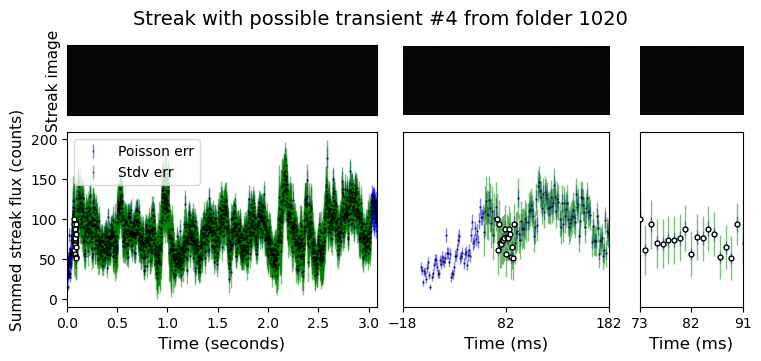

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.42857142857143


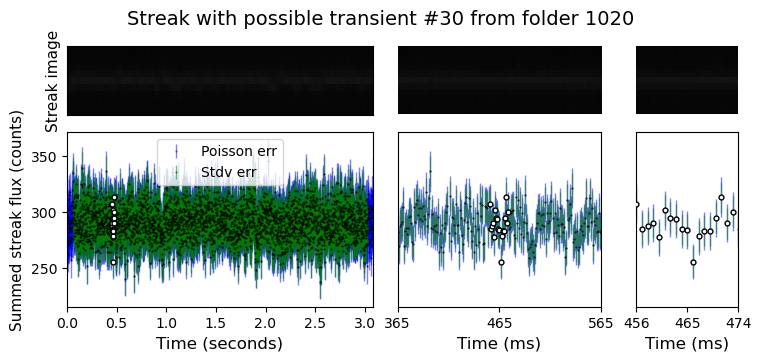

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  40.0


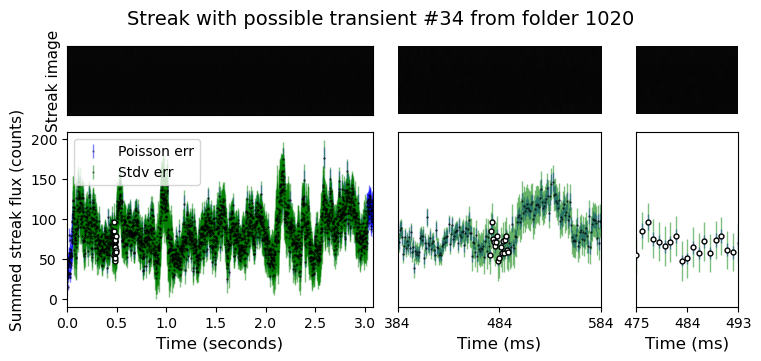

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.5


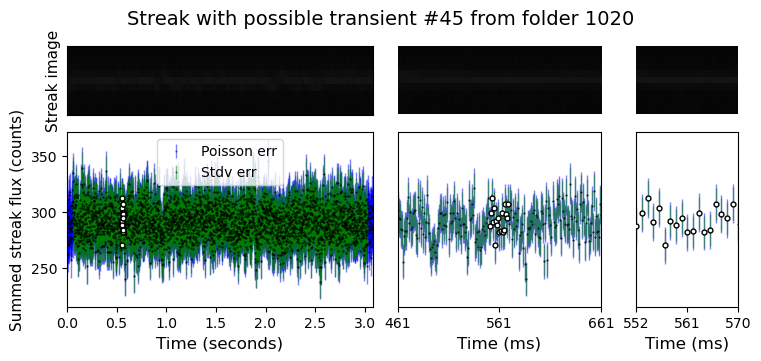

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  40.0


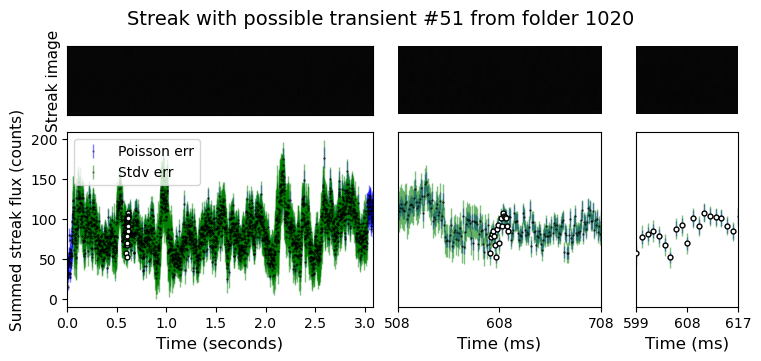

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.0


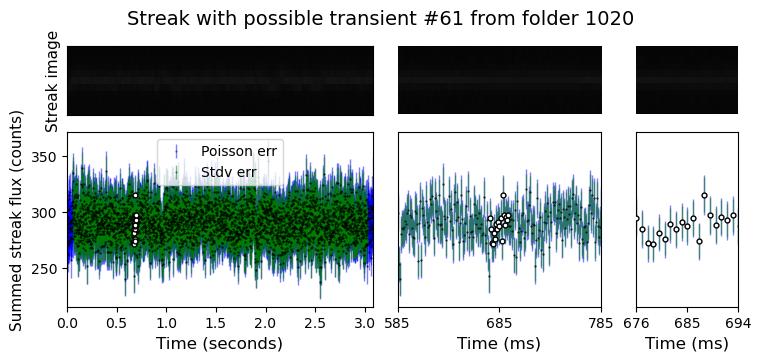

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.0


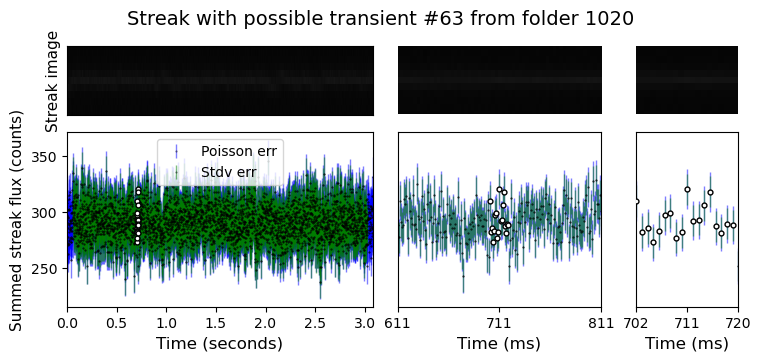

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.0


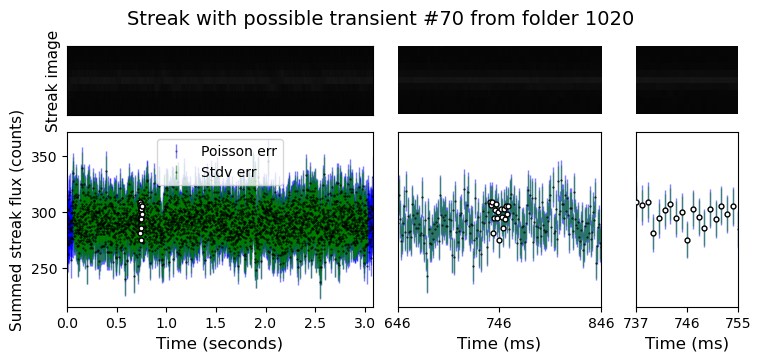

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.4


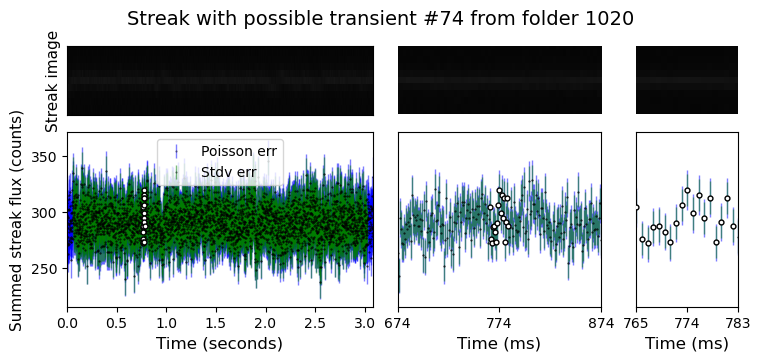

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  48.0


/home/3155/review_findings_functions.py:574: RuntimeWarning: invalid value encountered in sqrt
  sqrt = np.sqrt(tot)


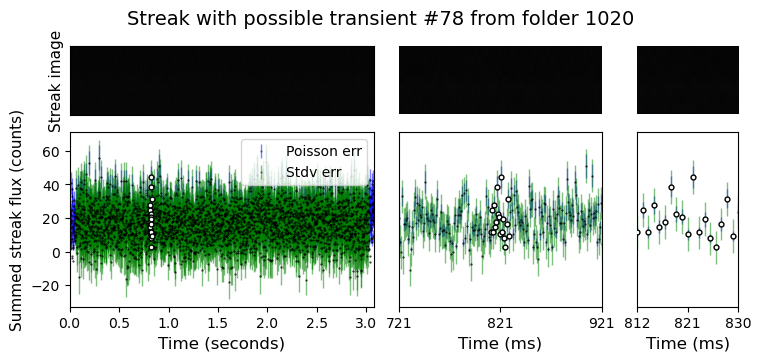

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  48.0


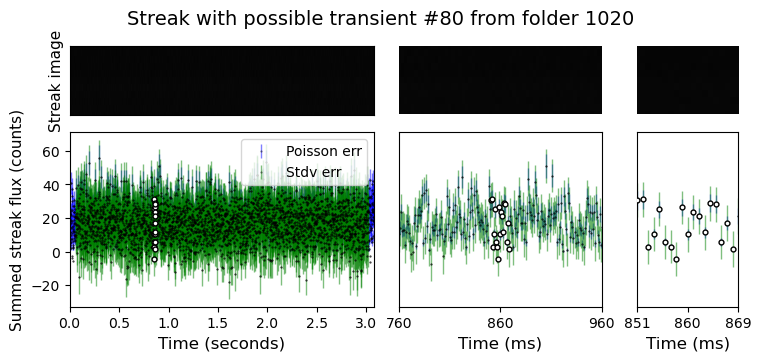

image (below): ztf_20221020154120_000640_zi_c04_x_0005.
transient candidate in column (streak)  33.333333333333336


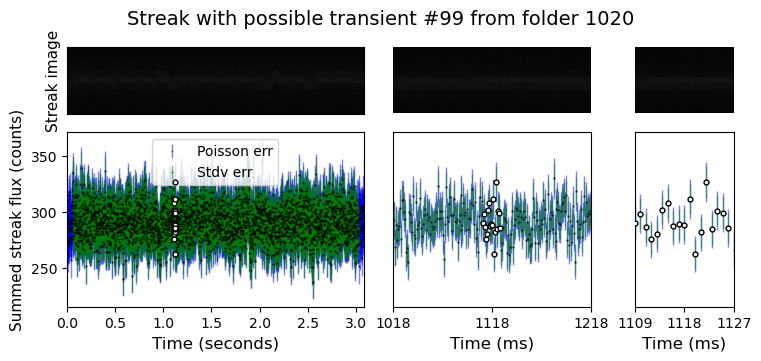

In [61]:
rff.inspect_df_time_series(alllist_stdv[np.abs(alllist_stdv['stdv_ratio'])>.5], alllist, '1020')

In [62]:
fname = '/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/ztf_20221020138241_000686_zi_c02_x_0017.fits.fz'

In [63]:
 hdul=fits.open(fname)
    # print(path)
file1_array = hdul[1].data

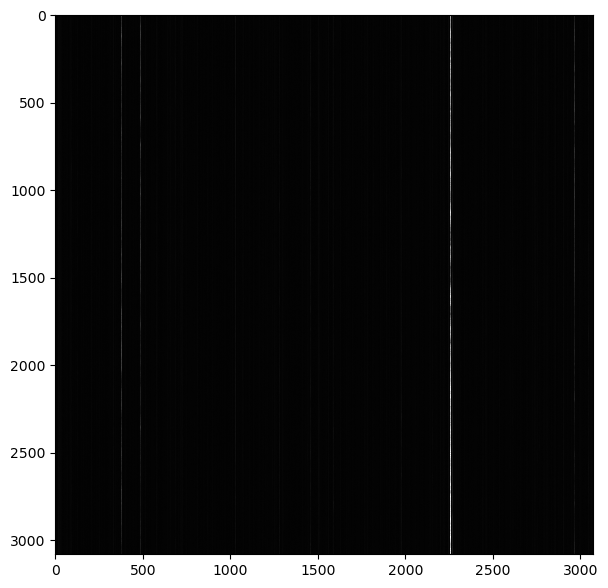

In [64]:
plt.imshow(file1_array)

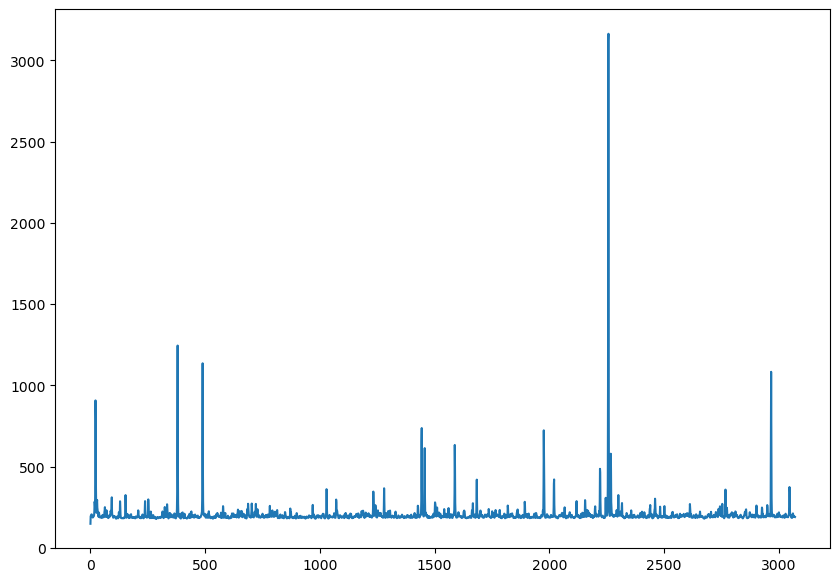

In [87]:
plt.plot(np.average(file1_array, axis=0))

In [74]:
np.linspace(0, len(np.sum(file1_array, axis=0)), len(np.sum(file1_array, axis=0))+1)

array([0.000e+00, 1.000e+00, 2.000e+00, ..., 3.070e+03, 3.071e+03,
       3.072e+03])

In [ ]:
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

In [ ]:
'''

HERE I AM GETTING THE APERATURE SIZE

'''

In [137]:
def gaussian(x, amp, cen, sigma):
    return amp * np.exp(-(x - cen)**2 / (2 * sigma**2))

def get_widths(fname, method='avg'):
    hdul=fits.open(fname)
        # print(path)
    file1_array = hdul[1].data
    
    background = rff.get_image_background(file1_array)
    
            #subtracting background
    imagenobackground = file1_array - np.full(np.shape(file1_array),background)
    
    # Example data (replace this with your numpy array)
    if method=='avg':
        x = np.linspace(0, len(np.average(imagenobackground, axis=0))-1, len(np.average(imagenobackground, axis=0)))
        y = np.average(imagenobackground, axis=0)
    else:
        x = np.linspace(0, len(np.average(imagenobackground, axis=0))-1, len(np.average(imagenobackground, axis=0)))
        y = imagenobackground[1000,:]
    
    # Step 1: Find peaks
    peaks, _ = find_peaks(y, height=300)  # Adjust height threshold for your data
    
    # Step 2: Define Gaussian function
    
    
    # Initialize a list to store FWHM values
    fwhm_list = []
    
    # Step 3: Fit Gaussian to each peak and calculate FWHM
    for peak in peaks:
        # Select a region around the peak for fitting
        left = max(0, peak - 20)
        right = min(len(x), peak + 20)
        x_fit = x[left:right]
        y_fit = y[left:right]
        
        # Initial guess for parameters: amplitude, center, and width
        p0 = [y[peak], x[peak], 1]
        
        # Use bounds to guide the fitting process
        bounds = ([0, x[peak]-5, 0], [np.inf, x[peak]+5, np.inf])  # Constrain width and center
        
        try:
            # Increase maxfev to allow more function evaluations
            popt, _ = curve_fit(gaussian, x_fit, y_fit, p0=p0, bounds=bounds, maxfev=2000)
            
            # Extract fitted parameters
            amp, cen, sigma = popt
            fwhm = 2.355 * sigma  # FWHM formula
            
            # Store FWHM in the list
            fwhm_list.append(fwhm)
            
            # # Plot the data and fitted Gaussian
            # plt.plot(x, y, label='Data')
            # plt.plot(x_fit, gaussian(x_fit, *popt), label=f'Fitted peak at {cen:.2f} with FWHM={fwhm:.2f}')
            # plt.legend()
    
        except RuntimeError as e:
            print(f"Could not fit peak at x={x[peak]}: {e}")
    return fwhm_list
    # Output the list of FWHM values
    # print("FWHM values for detected peaks:", fwhm_list)


# plt.show()


In [114]:
print("FWHM values for detected peaks:", fwhm_list)

FWHM values for detected peaks: [2.1202410841809978, 1.9667975726378308, 1.9771473177285903, 2.0500449186285157, 1.9131843826778496, 2.0473038976248765, 2.0581365508812834, 2.0877762876815558, 2.1973508075584025, 2.1405328494916693]


In [100]:
np.average(fwhm_list)

2.055851566909157

In [138]:
get_widths(fname, method=1000)

[2.1111835645244774,
 1.7171407284405507,
 1.9690965731361532,
 2.11152745806742,
 1.8442593191691063,
 1.9825723288773476,
 1.8587956305276272,
 2.267579036979237,
 2.323422228908933,
 1.5835857408912368,
 2.2548510346391626]

In [109]:
path = '/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/'


In [120]:
files = ['ztf_20221020138241_000686_zi_c02_x_0017.fits.fz',
         'ztf_20221020154120_000640_zi_c05_x_0020.fits.fz',  'ztf_20221020297847_000449_zr_c04_x_0005.fits.fz',
'ztf_20221020154120_000640_zi_c05_x_0021.fits.fz',  'ztf_20221020297847_000449_zr_c04_x_0006.fits.fz',
'ztf_20221020154120_000640_zi_c05_x_0022.fits.fz',  'ztf_20221020297847_000449_zr_c04_x_0007.fits.fz',
'ztf_20221020154120_000640_zi_c05_x_0023.fits.fz',  'ztf_20221020297847_000449_zr_c04_x_0008.fits.fz',
'ztf_20221020154120_000640_zi_c05_x_0024.fits.fz',  'ztf_20221020297847_000449_zr_c04_x_0009.fits.fz',
'ztf_20221020154120_000640_zi_c05_x_0025.fits.fz',  'ztf_20221020297847_000449_zr_c04_x_0010.fits.fz',
'ztf_20221020154120_000640_zi_c05_x_0026.fits.fz',  'ztf_20221020297847_000449_zr_c04_x_0011.fits.fz',
'ztf_20221020154120_000640_zi_c05_x_0027.fits.fz',  'ztf_20221020297847_000449_zr_c04_x_0012.fits.fz',
'ztf_20221020154120_000640_zi_c05_x_0028.fits.fz',  'ztf_20221020297847_000449_zr_c04_x_0013.fits.fz',
'ztf_20221020154120_000640_zi_c05_x_0029.fits.fz',  'ztf_20221020297847_000449_zr_c04_x_0014.fits.fz',
'ztf_20221020154120_000640_zi_c06_x_0000.fits.fz',  'ztf_20221020297847_000449_zr_c04_x_0015.fits.fz']


In [129]:
len(files)

23

In [144]:
fwhms_2 = []
for file in files:
    fpath = path+file
    f_list = get_widths(fpath, method=1000)
    for el in f_list:
        fwhms_2.append(el)

In [145]:
fwhms_2

[2.1111835645244774,
 1.7171407284405507,
 1.9690965731361532,
 2.11152745806742,
 1.8442593191691063,
 1.9825723288773476,
 1.8587956305276272,
 2.267579036979237,
 2.323422228908933,
 1.5835857408912368,
 2.2548510346391626,
 1.9921539845722251,
 2.141383991430343,
 2.0286357939175734,
 1.9598193471681584,
 4.2417113608605055,
 2.076280259775748,
 1.9224783380084343,
 2.1573300669988833,
 1.7434151924851602,
 1.6320519037225407,
 1.6190379609396528,
 2.3087144498323338,
 2.212254913556136,
 2.2543441644860978,
 2.0306776562783155,
 1.7712150670132096,
 2.0918873334415045,
 1.7653489714656043,
 1.829035301942738,
 1.505749609234105,
 2.0866489057156175,
 1.8724894758911494,
 1.600138753152626,
 2.5403054215445136,
 2.190520139633412,
 1.8617594093860412,
 1.6346702291857396,
 2.0119882066898542,
 1.868874538427696,
 1.584722745512721,
 1.9909486373440115,
 2.088283429188786,
 1.9664104186540354,
 1.7007823860242248,
 1.6829624096032352,
 1.9089637993521316,
 1.6676741894006675,
 1.938

In [146]:
4*np.average(fwhms_2)/2.35 #two sigma

3.8338827019111763